# Пайплайн 2. Регионы согласованного изменения, несогласованность профиля и пространственные модули: реальные данные

Исследовательский пайплайн «приумножить»: вместо очередного алгоритма кластеризации CpG он строит новое
представление метилома и проверяет его на независимой когорте.

| Блок | Новый объект или вопрос | Как проверяется |
|---|---|---|
| M1 | **Регион согласованного изменения**: CpG объединяются, если их возрастные наклоны однородны (внутри координатного каркаса DBSCAN) | Однородность наклонов в независимой когорте; точность и переносимость часов |
| M2 | **Измерительная модель региона**: сдвиг \(\hat u\) относительно обучающего профиля CpG и несогласованность \(D\) с учётом покрытия | mean → shift → shift+disc; ассоциация \(D\) с возрастом сверх сдвига и покрытия с репликацией; индекс несогласованности при CR; обогащение по ChromHMM |
| M3 | **Пространственные модули**: регионы, связанные контактом Hi-C и остаточной ко-метилированностью | Контакты против случайных пар на том же расстоянии в двух когортах; модули против модулей из случайных пар |
| M4 | **Переносимость оценки** при смене набора CpG | Split-half надёжность mean β против shift; калибровка стандартной ошибки; удаление CpG и прореживание чтений |

**Данные** те же, что в пайплайне 1: GSE80672 (Petkovich, обучение/внутренний тест/CR), GSE120132 (Thompson,
внешний тест), full-stack ChromHMM mm10, Hi-C CH12 и mESC (4DN). Требования: Google Colab, ~10 ГБ диска,
около 40–60 мин. Если пайплайн 1 уже выполнялся с тем же `WORK`, загруженные данные и матрица переиспользуются.

**Статус метода.** Это прототип исследовательской гипотезы, а не опубликованный метод с доказанной новизной.
Несогласованность \(D\) — статистическая характеристика bulk-профиля относительно обучающего референса, не
прямое измерение внутриклеточной дезорганизации; клеточный состав крови в данных не измерен.


> **Выполненная версия.** Блокнот выполнен целиком через `jupyter nbconvert --execute` 14.10.2026 в изолированной Linux-среде (2 CPU, 7 ГБ ОЗУ, Python 3.14), рабочий каталог `/tmp/work`; код идентичен чистой версии в `notebooks/`, все выводы ниже — реальные результаты этого прогона.

## 1. Конфигурация
Все пути задаются здесь. По умолчанию в Colab используется `/content/regclock_work`; чтобы не скачивать
данные повторно, можно указать каталог на Google Drive (ячейка ниже монтирует Drive при `USE_DRIVE=True`).

In [1]:
import os, sys, json, time, subprocess, shutil
IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False                      # True — хранить данные и кэш на Google Drive
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/regclock_work"
else:
    WORK = os.environ.get("REGCLOCK_WORK", "/content/regclock_work" if IN_COLAB else os.path.abspath("regclock_work"))
DATA = os.environ.get("REGCLOCK_DATA", os.path.join(WORK, "data"))
OUT = os.path.join(WORK, "results_pipeline2")
CODE = os.path.join(WORK, "code")
for d in (WORK, DATA, OUT, CODE):
    os.makedirs(d, exist_ok=True)
sys.path.insert(0, CODE)

SEED = 20261014          # фиксированное зерно для разбиения и всех случайных процедур
MIN_COV = 5              # минимальное покрытие CpG (как в RegBC)
MIN_FRAC_TRAIN = 0.5     # словарь CpG: покрытие >= MIN_COV у >= 50% обучающих образцов
QC_FRAC_CPG = 0.9        # ветка A: отдельные CpG с покрытием >= MIN_COV у >= 90% обучающих образцов
DBSCAN_EPS, DBSCAN_MINPTS = 1000, 5   # параметры eps1000 DRegBC (Simpson et al., 2023)
RUN_HIC = True           # загрузка Hi-C из 4DN (CH12 ~4.5 ГБ, mESC ~1.5 ГБ; после извлечения удаляются)
print("WORK =", WORK)

WORK = /tmp/work


## 2. Установка зависимостей
Python: `cooler` для чтения `.mcool` Hi-C. Пайплайн 2 не требует R.

In [2]:
def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if r.stdout.strip():
        print(r.stdout[-3000:])
    if r.returncode != 0:
        print(r.stderr[-3000:])
        if check:
            raise RuntimeError(f"Команда завершилась с кодом {r.returncode}")
    return r

sh(f"{sys.executable} -m pip install -q cooler pyarrow scikit-learn scipy pandas numpy matplotlib")

$ /usr/local/bin/python3.14 -m pip install -q cooler pyarrow scikit-learn scipy pandas numpy matplotlib


CompletedProcess(args='/usr/local/bin/python3.14 -m pip install -q cooler pyarrow scikit-learn scipy pandas numpy matplotlib', returncode=0, stdout='', stderr='')

## 3. Код модулей
Ячейки ниже записывают четыре модуля в `WORK/code`: сборка когорт (`data_build.py`), регионы/признаки/модели
(`core.py`), извлечение контактов Hi-C (`hic_extract.py`) и новые методы пайплайна 2 (`coherence.py`). Код полностью приведён в ноутбуке.

In [3]:
%%writefile {CODE}/data_build.py
"""Сборка реальных когорт RRBS крови мыши (mm10) для обоих пайплайнов.

Источники (NCBI GEO, открытый доступ):
  * GSE80672 (Petkovich et al., 2017) — кровь C57BL/6, переобработка в mm10
    из GSE120136 (BS-Seeker2, файлы CGfinal), используется как обучающая когорта;
  * GSE120132 (Thompson et al., 2018) — кровь C57BL/6J и BALB/cByJ, те же CGfinal mm10,
    используется как независимая внешняя когорта.
Формат CGfinal (описание GSE120136): chromosome, dinucleotide, position,
methylated counts, total counts, methylation frequency, 95% CI.
"""
import gzip, io, os, re, subprocess, time, urllib.request
import numpy as np
import pandas as pd

AUTOSOMES = [f"chr{i}" for i in range(1, 20)]
CHR_INDEX = {c: i for i, c in enumerate(AUTOSOMES)}
GEO = "https://ftp.ncbi.nlm.nih.gov/geo"
PETKOVICH_TAR = f"{GEO}/series/GSE120nnn/GSE120136/suppl/GSE120136_GSE80672_re-analyzed_Samples_processed_data.tar.gz"
PETKOVICH_MATRIX = f"{GEO}/series/GSE80nnn/GSE80672/matrix/GSE80672_series_matrix.txt.gz"
THOMPSON_MATRICES = [f"{GEO}/series/GSE120nnn/GSE120132/matrix/GSE120132-GPL17021_series_matrix.txt.gz",
                     f"{GEO}/series/GSE120nnn/GSE120132/matrix/GSE120132-GPL21103_series_matrix.txt.gz"]
THOMPSON_FILELIST = f"{GEO}/series/GSE120nnn/GSE120132/suppl/filelist.txt"


def _get(url, dest):
    if not os.path.exists(dest) or os.path.getsize(dest) == 0:
        subprocess.run(["curl", "-sSfL", "--retry", "5", "-o", dest, url], check=True)
    return dest


def parse_series_matrix(path):
    rows = {}
    with gzip.open(path, "rt", errors="replace") as fh:
        for line in fh:
            if not line.startswith("!Sample_"):
                continue
            parts = [x.strip().strip('"') for x in line.rstrip("\n").split("\t")]
            key, vals = parts[0], parts[1:]
            if key == "!Sample_characteristics_ch1":
                name = vals[0].split(":")[0].strip()
                rows[name] = [v.split(":", 1)[1].strip() if ":" in v else v for v in vals]
            else:
                rows[key.replace("!Sample_", "")] = vals
    n = len(rows["geo_accession"])
    return pd.DataFrame({k: v for k, v in rows.items() if len(v) == n})


def petkovich_metadata(workdir):
    p = _get(PETKOVICH_MATRIX, os.path.join(workdir, "GSE80672_series_matrix.txt.gz"))
    m = parse_series_matrix(p)
    # В GEO поле подписано "age (years)", но значения 0.67–35 соответствуют месяцам
    # (Petkovich et al., 2017: мыши 3–35 мес.). Перевод не выполняется, единица — месяцы.
    m["age_months"] = pd.to_numeric(m["age (years)"], errors="coerce")
    base = (m["tissue"].str.lower() == "whole blood") & (m["strain"] == "C57BL/6") & \
           (m["genetic condition"] == "Wild Type")
    m["group"] = np.where(base & (m["diet"] == "standard"), "petkovich_control",
                  np.where(base & (m["diet"] == "Calorie Restricted"), "petkovich_CR", "excluded"))
    m = m[m.group != "excluded"].copy()
    m["sample_id"] = m["geo_accession"]
    m["cohort"] = "GSE80672"
    m["sex"] = m["gender"]
    return m[["sample_id", "title", "cohort", "group", "age_months", "sex", "strain", "diet"]].reset_index(drop=True)


def thompson_metadata(workdir):
    ms = []
    for u in THOMPSON_MATRICES:
        ms.append(parse_series_matrix(_get(u, os.path.join(workdir, os.path.basename(u)))))
    m = pd.concat(ms, ignore_index=True)
    m = m[m["tissue"] == "Blood"].copy()
    m["age_months"] = m["age"].str.replace("mo", "", regex=False).astype(float)
    m["group"] = np.where(m["strain"] == "C57BL/6J", "thompson_B6", "thompson_BALB")
    m["sample_id"] = m["geo_accession"]
    m["cohort"] = "GSE120132"
    m["sex"] = m["Sex"]
    m["diet"] = "standard"
    return m[["sample_id", "title", "cohort", "group", "age_months", "sex", "strain", "diet"]].reset_index(drop=True)


def download_petkovich(datadir, keep_ids):
    """Потоковая распаковка архива GSE120136 (~2.4 ГБ); на диске остаются только нужные образцы."""
    os.makedirs(datadir, exist_ok=True)
    done = os.path.join(datadir, ".done")
    if not os.path.exists(done):
        cmd = f"curl -sSfL --retry 5 '{PETKOVICH_TAR}' | tar xzf - -C '{datadir}'"
        subprocess.run(cmd, shell=True, check=True)
        open(done, "w").close()
    paths = {}
    for f in os.listdir(datadir):
        mm = re.match(r"GSE80672_(GSM\d+)\.CGfinal\.txt\.gz", f)
        if mm:
            if mm.group(1) in keep_ids:
                paths[mm.group(1)] = os.path.join(datadir, f)
            else:
                os.remove(os.path.join(datadir, f))
    return paths


def download_thompson(datadir, keep_ids, workers=6):
    os.makedirs(datadir, exist_ok=True)
    fl = _get(THOMPSON_FILELIST, os.path.join(datadir, "filelist.txt"))
    names = [l.split("\t")[1] for l in open(fl) if "Mouse_Blood" in l]
    paths, jobs = {}, []
    for n in names:
        gsm = n.split("_")[0]
        if gsm not in keep_ids:
            continue
        dest = os.path.join(datadir, n)
        paths[gsm] = dest
        if not os.path.exists(dest) or os.path.getsize(dest) == 0:
            jobs.append(f"{GEO}/samples/{gsm[:-3]}nnn/{gsm}/suppl/{n} {dest}")
    if jobs:
        lst = os.path.join(datadir, "jobs.txt")
        open(lst, "w").write("\n".join(jobs) + "\n")
        subprocess.run(f"cat '{lst}' | xargs -P {workers} -n 2 sh -c 'curl -sSfL --retry 5 -o \"$1\" \"$0\"'",
                       shell=True, check=True)
    return paths


def read_cgfinal(path, min_cov=1):
    """Возвращает (key, mC, cov) для аутосом; key = chr_index * 2^32 + pos (исходная позиция CGfinal)."""
    d = pd.read_csv(path, sep=r"\s+", header=None, usecols=[0, 2, 3, 4],
                    names=["chr", "pos", "mc", "cov"], engine="c",
                    dtype={"chr": str, "pos": np.int64, "mc": np.int64, "cov": np.int64})
    d = d[d["chr"].isin(CHR_INDEX) & (d["cov"] >= min_cov)]
    if (d["mc"] > d["cov"]).any() or (d["mc"] < 0).any():
        raise ValueError(f"Нарушено 0 <= mC <= coverage в {path}")
    key = d["chr"].map(CHR_INDEX).values.astype(np.int64) * (1 << 32) + d["pos"].values
    if len(np.unique(key)) != len(key):
        raise ValueError(f"Дубликаты координат в {path}")
    return key, d["mc"].values, d["cov"].values


def build_matrix(samples, paths, train_ids, out_npz, min_cov=5, min_frac_train=0.5, log=print):
    """Два прохода: (1) словарь сайтов по обучающим образцам; (2) counts всех образцов на этом словаре.
    Словарь зависит только от покрытия обучающих образцов (без возраста)."""
    if os.path.exists(out_npz):
        z = np.load(out_npz, allow_pickle=True)
        return z["keys"], z["mc"], z["cov"], list(z["sample_ids"])
    t0 = time.time()
    batch_u, batch_c, buf = [], [], []
    def flush():
        if buf:
            u, c = np.unique(np.concatenate(buf), return_counts=True)
            batch_u.append(u); batch_c.append(c); buf.clear()
    for k, sid in enumerate(train_ids):
        key, mc, cov = read_cgfinal(paths[sid])
        buf.append(key[cov >= min_cov])
        if len(buf) == 20:
            flush()
        if (k + 1) % 20 == 0:
            log(f"  проход 1: {k+1}/{len(train_ids)} обучающих образцов, {time.time()-t0:.0f} с")
    flush()
    allu = np.concatenate(batch_u); allc = np.concatenate(batch_c)
    order = np.argsort(allu, kind="stable"); allu, allc = allu[order], allc[order]
    uu, start = np.unique(allu, return_index=True)
    tot = np.add.reduceat(allc, start)
    keys = uu[tot >= min_frac_train * len(train_ids)]
    log(f"  словарь: {len(keys)} CpG с покрытием >= {min_cov} у >= {min_frac_train:.0%} обучающих образцов")
    ids = list(samples)
    MC = np.zeros((len(ids), len(keys)), dtype=np.uint16)
    CV = np.zeros((len(ids), len(keys)), dtype=np.uint16)
    for k, sid in enumerate(ids):
        key, mc, cov = read_cgfinal(paths[sid])
        idx = np.searchsorted(keys, key)
        idx[idx == len(keys)] = 0
        hit = keys[idx] == key
        # Ограничение uint16: при покрытии > 65535 counts масштабируются пропорционально (практически не встречается)
        cv = cov[hit].astype(np.float64); mcv = mc[hit].astype(np.float64)
        scale = np.where(cv > 65535, 65535 / cv, 1.0)
        CV[k, idx[hit]] = np.round(cv * scale).astype(np.uint16)
        MC[k, idx[hit]] = np.round(mcv * scale).astype(np.uint16)
        if (k + 1) % 25 == 0:
            log(f"  проход 2: {k+1}/{len(ids)} образцов, {time.time()-t0:.0f} с")
    np.savez(out_npz, keys=keys, mc=MC, cov=CV, sample_ids=np.array(ids))
    return keys, MC, CV, ids


def key_chr(keys):
    return (keys >> 32).astype(np.int32)


def key_pos(keys):
    return (keys & ((1 << 32) - 1)).astype(np.int64)


Overwriting /tmp/work/code/data_build.py


In [4]:
%%writefile {CODE}/core.py
"""Общие функции: регионы, региональные признаки, модель возраста, метрики."""
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.cluster import DBSCAN
from sklearn.linear_model import LassoCV, Lasso, lasso_path
from sklearn.model_selection import KFold
from scipy import stats

MIN_COV = 5


# ----------------------------------------------------------------------------- данные
class Methylome:
    """Обёртка над матрицей counts: образцы × CpG (uint16)."""

    def __init__(self, keys, mc, cov, sample_ids, meta):
        self.keys = keys
        self.chr = (keys >> 32).astype(np.int32)
        self.pos = (keys & ((1 << 32) - 1)).astype(np.int64)
        self.mc = mc
        self.cov = cov
        self.ids = list(sample_ids)
        self.meta = meta.set_index("sample_id").loc[self.ids].reset_index()
        self.row = {s: i for i, s in enumerate(self.ids)}

    def rows(self, split):
        return np.where(self.meta["split"].values == split)[0]

    def beta(self, rows, sites=None, mc=None, cov=None, min_cov=MIN_COV):
        mc = self.mc if mc is None else mc
        cov = self.cov if cov is None else cov
        sites = np.arange(cov.shape[1]) if sites is None else np.asarray(sites)
        rows = np.asarray(rows)
        b = np.full((len(rows), len(sites)), np.nan, dtype=np.float32)
        for j0 in range(0, len(sites), 100000):  # поблочно: пиковая память ~ размер результата
            sj = sites[j0:j0 + 100000]
            c = cov[np.ix_(rows, sj)].astype(np.float32)
            m = mc[np.ix_(rows, sj)].astype(np.float32)
            with np.errstate(invalid="ignore", divide="ignore"):
                b[:, j0:j0 + 100000] = np.where(c >= min_cov, m / c, np.nan)
        return b


def degrade_counts(mc, cov, mode, level, rng):
    """mode='mask': случайно удалить долю `level` наблюдаемых CpG;
    mode='thin': биномиальное прореживание чтений с вероятностью сохранения `level`."""
    mc = mc.astype(np.int64); cov = cov.astype(np.int64)
    if mode == "mask":
        drop = rng.random(cov.shape) < level
        cov = np.where(drop, 0, cov); mc = np.where(drop, 0, mc)
    elif mode == "thin":
        m2 = rng.binomial(mc, level)
        u2 = rng.binomial(cov - mc, level)
        mc, cov = m2, m2 + u2
    return mc.astype(np.uint16), cov.astype(np.uint16)


# ----------------------------------------------------------------------------- регионы
def regions_from_labels(chr_, pos, labels, site_idx):
    """labels >= 0 — номер региона для сайтов site_idx; возвращает таблицу регионов и массив принадлежности."""
    df = pd.DataFrame({"site": site_idx, "chr": chr_[site_idx], "pos": pos[site_idx], "lab": labels})
    df = df[df.lab >= 0]
    g = df.groupby("lab", sort=False)
    reg = pd.DataFrame({"chr": g.chr.first(), "start": g.pos.min(), "end": g.pos.max() + 2, "n_cpg": g.size()})
    reg = reg.sort_values(["chr", "start"]).reset_index()
    remap = pd.Series(np.arange(len(reg)), index=reg["lab"].values)
    member = np.full(len(chr_), -1, dtype=np.int64)
    member[df.site.values] = remap.loc[df.lab.values].values
    return reg.drop(columns="lab"), member


def dbscan_regions(chr_, pos, site_idx, eps=1000, min_samples=5):
    """DBSCAN по геномной координате (как DRegBC в Simpson et al., 2023: eps в п.н., minPts=5)."""
    labels = np.full(len(site_idx), -1, dtype=np.int64)
    offset = 0
    c = chr_[site_idx]
    for ch in np.unique(c):
        w = np.where(c == ch)[0]
        x = pos[site_idx[w]].reshape(-1, 1).astype(np.float64)
        lab = DBSCAN(eps=eps, min_samples=min_samples, algorithm="kd_tree").fit_predict(x)
        ok = lab >= 0
        labels[w[ok]] = lab[ok] + offset
        offset += (lab.max() + 1) if ok.any() else 0
    return regions_from_labels(chr_, pos, labels, site_idx)


def window_regions(chr_, pos, site_idx, width=5000, min_cpg=1):
    """Скользящие (непересекающиеся) окна фиксированной длины, как RegBC 5 kb."""
    lab = chr_[site_idx].astype(np.int64) * 10**7 + pos[site_idx] // width
    u, inv, cnt = np.unique(lab, return_inverse=True, return_counts=True)
    inv = np.where(cnt[inv] >= min_cpg, inv, -1)
    return regions_from_labels(chr_, pos, inv, site_idx)


def interval_regions(chr_, pos, site_idx, intervals, min_cpg=3):
    """Регионы по внешним интервалам (BED, 0-based полуоткрытые) — например, MethyLasso или ChromHMM.
    intervals: DataFrame chr(int-индекс), start, end, неперекрывающиеся."""
    labels = np.full(len(site_idx), -1, dtype=np.int64)
    c = chr_[site_idx]; p = pos[site_idx]
    for ch, iv in intervals.groupby("chr"):
        iv = iv.sort_values("start")
        w = np.where(c == ch)[0]
        if len(w) == 0:
            continue
        # CGfinal-позиции трактуются как 1-based координата C; BED-интервал [start, end) 0-based
        p0 = p[w] - 1
        k = np.searchsorted(iv.start.values, p0, side="right") - 1
        ok = (k >= 0) & (p0 < iv.end.values[np.clip(k, 0, None)])
        labels[w[ok]] = iv.index.values[k[ok]]
    reg, member = regions_from_labels(chr_, pos, labels, site_idx)
    keep = reg.n_cpg.values >= min_cpg
    newid = np.full(len(reg), -1); newid[keep] = np.arange(keep.sum())
    member = np.where(member >= 0, newid[np.clip(member, 0, None)], -1)
    return reg[keep].reset_index(drop=True), member


def intersect_partitions(member_a, member_b, chr_, pos, min_cpg=3):
    """Пересечение двух разбиений: сайт остаётся в регионе, только если он принадлежит обоим."""
    ok = (member_a >= 0) & (member_b >= 0)
    lab = np.where(ok, member_a.astype(np.int64) * 10**7 + member_b, -1)
    site_idx = np.where(ok)[0]
    u, inv = np.unique(lab[site_idx], return_inverse=True)
    reg, member = regions_from_labels(chr_, pos, inv, site_idx)
    keep = reg.n_cpg.values >= min_cpg
    newid = np.full(len(reg), -1); newid[keep] = np.arange(keep.sum())
    member = np.where(member >= 0, newid[np.clip(member, 0, None)], -1)
    return reg[keep].reset_index(drop=True), member


# ----------------------------------------------------------------------------- признаки
def _assign(member, xnorm=None, nbins=None):
    sites = np.where(member >= 0)[0]
    nreg = member.max() + 1
    if nbins is None:
        cols = member[sites]; ncol = nreg
    else:
        b = np.minimum((xnorm[sites] * nbins).astype(np.int64), nbins - 1)
        cols = member[sites] * nbins + b; ncol = nreg * nbins
    A = sp.csr_matrix((np.ones(len(sites), np.float32), (np.arange(len(sites)), cols)), shape=(len(sites), ncol))
    return sites, A


def relative_position(member, pos):
    """Нормированная координата CpG внутри региона: 0 — первый CpG, 1 — последний."""
    x = np.zeros(len(member), np.float32)
    s = np.where(member >= 0)[0]
    m = member[s]
    mn = pd.Series(pos[s]).groupby(m).transform("min").values
    mx = pd.Series(pos[s]).groupby(m).transform("max").values
    x[s] = (pos[s] - mn) / np.maximum(mx - mn, 1)
    return x


def region_features(M, rows, member, kinds=("mean",), nbins=4, mc=None, cov=None, chunk=40, min_obs_pattern=3):
    """Признаки региона по наблюдаемым CpG (покрытие >= MIN_COV) каждого образца.
    mean — среднее beta; sd — стандартное отклонение между CpG; slope — наклон beta по нормированной
    координате; enddiff — среднее последней трети минус среднее первой трети; bins — средние nbins
    последовательных бинов. Пустые значения = NaN (далее импутируются медианой train)."""
    x = relative_position(member, M.pos)
    sites, A = _assign(member)
    xs = x[sites]
    Ax = sp.csr_matrix(A.multiply(xs[:, None])); Ax2 = sp.csr_matrix(A.multiply((xs ** 2)[:, None]))
    first = sp.csr_matrix(A.multiply((xs <= 1 / 3)[:, None].astype(np.float32)))
    last = sp.csr_matrix(A.multiply((xs >= 2 / 3)[:, None].astype(np.float32)))
    if "bins" in kinds:
        _, Ab = _assign(member, x, nbins)
    out = {k: [] for k in kinds}
    for s0 in range(0, len(rows), chunk):
        r = rows[s0:s0 + chunk]
        B = M.beta(r, sites, mc=mc, cov=cov)
        O = np.isfinite(B).astype(np.float32)
        B0 = np.nan_to_num(B)
        n = O @ A; sb = B0 @ A
        with np.errstate(invalid="ignore", divide="ignore"):
            mean = sb / n
            if "mean" in kinds:
                out["mean"].append(mean)
            if "sd" in kinds:
                sb2 = (B0 ** 2) @ A
                var = sb2 / n - mean ** 2
                sd = np.sqrt(np.clip(var * n / np.maximum(n - 1, 1), 0, None))
                sd[n < min_obs_pattern] = np.nan
                out["sd"].append(sd)
            if "slope" in kinds:
                sx = O @ Ax; sx2 = O @ Ax2; sxb = B0 @ Ax
                den = n * sx2 - sx ** 2
                slope = (n * sxb - sx * sb) / den
                slope[(n < min_obs_pattern) | (np.abs(den) < 1e-6)] = np.nan
                out["slope"].append(slope)
            if "enddiff" in kinds:
                nf = O @ first; nl = O @ last
                d = (B0 @ last) / nl - (B0 @ first) / nf
                d[(nf < 1) | (nl < 1)] = np.nan
                out["enddiff"].append(d)
            if "bins" in kinds:
                nb = O @ Ab
                out["bins"].append((B0 @ Ab) / nb)
    return {k: np.vstack(v).astype(np.float32) for k, v in out.items()}


def cpg_features(M, rows, sites, mc=None, cov=None):
    return M.beta(rows, sites, mc=mc, cov=cov)


# ----------------------------------------------------------------------------- модель
class Preprocessor:
    """Импутация медианой train и стандартизация по train; признаки без наблюдений в train удаляются."""

    def fit(self, X):
        p = X.shape[1]
        self.med = np.full(p, np.nan, np.float32); self.mu = np.zeros(p, np.float32); self.sd = np.zeros(p, np.float32)
        for j0 in range(0, p, 50000):
            blk = np.array(X[:, j0:j0 + 50000], dtype=np.float32)
            with np.errstate(all="ignore"):
                import warnings
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", RuntimeWarning)
                    med = np.nanmedian(blk, axis=0)
            bad = ~np.isfinite(blk)
            blk[bad] = np.broadcast_to(med, blk.shape)[bad]
            self.med[j0:j0 + 50000] = med; self.mu[j0:j0 + 50000] = blk.mean(0); self.sd[j0:j0 + 50000] = blk.std(0)
        self.keep = np.isfinite(self.med) & (self.sd > 1e-8)
        return self

    def transform(self, X):
        # одна копия: отбор столбцов, затем импутация и стандартизация на месте (экономия памяти при ~10^6 CpG)
        Z = np.array(X[:, self.keep], dtype=np.float32, order="F")
        med, mu, sd = self.med[self.keep], self.mu[self.keep], self.sd[self.keep]
        for j0 in range(0, Z.shape[1], 50000):
            blk = Z[:, j0:j0 + 50000]
            bad = ~np.isfinite(blk)
            if bad.any():
                blk[bad] = np.broadcast_to(med[j0:j0 + 50000], blk.shape)[bad]
            blk -= mu[j0:j0 + 50000]; blk /= sd[j0:j0 + 50000]
        return Z

    def missing_fraction(self, X):
        return float(np.mean(~np.isfinite(X[:, self.keep])))


class AgeModel:
    """LASSO; alpha выбирается 5-кратной CV внутри train (одинаково для всех представлений)."""

    def __init__(self, seed=0, n_alphas=40, cv=5):
        self.seed, self.n_alphas, self.cv = seed, n_alphas, cv

    def fit(self, X, y):
        self.pre = Preprocessor().fit(X)
        Z = self.pre.transform(X)
        self.ymu = y.mean()
        self.m = LassoCV(alphas=self.n_alphas, cv=KFold(self.cv, shuffle=True, random_state=self.seed),
                         max_iter=20000, tol=1e-4, n_jobs=1, copy_X=False, random_state=self.seed).fit(Z, y)
        self.n_features = int(self.pre.keep.sum())
        self.n_selected = int((self.m.coef_ != 0).sum())
        return self

    def predict(self, X):
        return self.m.predict(self.pre.transform(X))

    def feature_missing(self, X):
        """Доля пропусков среди признаков с ненулевым коэффициентом."""
        idx = np.where(self.pre.keep)[0][self.m.coef_ != 0]
        return float(np.mean(~np.isfinite(X[:, idx]))) if len(idx) else np.nan


def metrics(y, p, n_boot=2000, seed=0):
    y = np.asarray(y, float); p = np.asarray(p, float)
    err = np.abs(p - y)
    rng = np.random.default_rng(seed)
    bs = [err[rng.integers(0, len(err), len(err))].mean() for _ in range(n_boot)]
    ss = ((y - y.mean()) ** 2).sum()
    return {"n": len(y), "MAE": err.mean(), "MAE_lo": np.percentile(bs, 2.5), "MAE_hi": np.percentile(bs, 97.5),
            "MedAE": np.median(err), "R2": 1 - ((y - p) ** 2).sum() / ss, "r": np.corrcoef(y, p)[0, 1],
            "bias": (p - y).mean()}


def paired_mae_diff(y, p1, p2, n_boot=2000, seed=0):
    """Бутстреп разности MAE(p1) - MAE(p2) на одних и тех же образцах."""
    e1 = np.abs(p1 - y); e2 = np.abs(p2 - y); rng = np.random.default_rng(seed)
    d = [(e1[i] - e2[i]).mean() for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))]
    return float((e1 - e2).mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))


def age_acceleration(pred_ctrl, age_ctrl, pred_case, age_case):
    """Остатки относительно линии pred ~ age, оценённой на контролях вне обучения."""
    b = np.polyfit(age_ctrl, pred_ctrl, 1)
    rc = pred_ctrl - np.polyval(b, age_ctrl); rk = pred_case - np.polyval(b, age_case)
    u = stats.mannwhitneyu(rk, rc)
    return {"median_resid_case": float(np.median(rk)), "median_resid_ctrl": float(np.median(rc)),
            "MWU_p": float(u.pvalue), "n_case": len(rk), "n_ctrl": len(rc)}


# ----------------------------------------------------------------------------- графовый штраф
def region_bins(reg, res=25000):
    return ((reg.start.values + reg.end.values) // 2 // res) * res


def contact_edges(reg, contacts, res=25000, nodes=None):
    """Рёбра между регионами, чьи 25-кб бины имеют контакт (O/E >= порога при извлечении).
    contacts: chr(int), start1, start2, oe. Вес ребра = log2(O/E)."""
    nodes = np.arange(len(reg)) if nodes is None else np.asarray(nodes)
    nd = pd.DataFrame({"node": np.arange(len(nodes)), "chr": reg.chr.values[nodes], "bin": region_bins(reg, res)[nodes]})
    e = contacts.merge(nd.rename(columns={"bin": "start1", "node": "a"}), on=["chr", "start1"]) \
                .merge(nd.rename(columns={"bin": "start2", "node": "b"}), on=["chr", "start2"])
    e = e[e.a != e.b]
    return pd.DataFrame({"a": e.a.values, "b": e.b.values, "w": np.log2(e.oe.values).astype(np.float32),
                         "chr": e.chr.values})


def linear_edges(reg, nodes, max_gap=100000):
    r = reg.iloc[nodes].reset_index(drop=True)
    o = np.lexsort((r.start.values, r.chr.values))
    a, b = o[:-1], o[1:]
    ok = (r.chr.values[a] == r.chr.values[b]) & (r.start.values[b] - r.end.values[a] <= max_gap)
    return pd.DataFrame({"a": a[ok], "b": b[ok], "w": np.ones(ok.sum(), np.float32), "chr": r.chr.values[a[ok]]})


def rewire_edges(edges, seed=0):
    """Рандомизация с сохранением степеней узлов: перестановка вторых концов рёбер внутри хромосомы."""
    rng = np.random.default_rng(seed)
    out = []
    for ch, e in edges.groupby("chr"):
        b = rng.permutation(e.b.values)
        out.append(pd.DataFrame({"a": e.a.values, "b": b, "w": e.w.values, "chr": ch}))
    e = pd.concat(out, ignore_index=True)
    e = e[e.a != e.b]
    return e


def incidence(edges, p):
    m = len(edges)
    if m == 0:
        return sp.csr_matrix((0, p))
    sw = np.sqrt(np.clip(edges.w.values, 0, None)).astype(np.float64)
    rows = np.repeat(np.arange(m), 2)
    cols = np.column_stack([edges.a.values, edges.b.values]).ravel()
    vals = np.column_stack([sw, -sw]).ravel()
    return sp.csr_matrix((vals, (rows, cols)), shape=(m, p))


def _graph_path(Z, yc, B, lam2, alphas):
    Xa = sp.vstack([sp.csr_matrix(Z), np.sqrt(lam2) * B]).tocsc() if lam2 > 0 else Z
    ya = np.concatenate([yc, np.zeros(B.shape[0])]) if lam2 > 0 else yc
    # lasso_path масштабирует квадратичную часть на 1/N; приводим alpha к масштабу числа реальных образцов
    N = Xa.shape[0]; scale = len(yc) / N
    _, coefs, _ = lasso_path(Xa, ya, alphas=alphas * scale, max_iter=5000, tol=1e-3)
    return coefs  # p × n_alphas


def graph_lasso_cv(Z, y, B, lam2_grid, n_alphas=30, cv=5, seed=0):
    """Выбор (lambda2, alpha) 5-кратной CV на train; Z — стандартизованные признаки train."""
    yc = y - y.mean()
    amax = np.abs(Z.T @ yc).max() / len(y)
    alphas = amax * np.logspace(0, -3, n_alphas)
    folds = list(KFold(cv, shuffle=True, random_state=seed).split(Z))
    res = []
    for lam2 in lam2_grid:
        mse = np.zeros(n_alphas)
        for tr, va in folds:
            mu = Z[tr].mean(0); ytr = y[tr]
            coefs = _graph_path(Z[tr] - mu, ytr - ytr.mean(), B, lam2, alphas)
            pred = (Z[va] - mu) @ coefs + ytr.mean()
            mse += ((pred - y[va][:, None]) ** 2).mean(0) / cv
        k = int(np.argmin(mse)); res.append((mse[k], lam2, alphas[k]))
    best = min(res, key=lambda t: t[0])
    mu = Z.mean(0)
    coef = _graph_path(Z - mu, yc, B, best[1], np.array([best[2]]))[:, 0]
    return {"coef": coef, "mu": mu, "ymu": y.mean(), "lam2": best[1], "alpha": best[2],
            "cv_mse": best[0], "grid": res}


Overwriting /tmp/work/code/core.py


In [5]:
%%writefile {CODE}/hic_extract.py
import cooler, numpy as np, pandas as pd, sys, time
def extract_contacts(mcool, res=25000, min_d_bins=2, max_d_bins=80, oe_min=2.0, raw_min=5, chroms=None, block=400):
    c = cooler.Cooler(f"{mcool}::resolutions/{res}")
    chroms = chroms or [f"chr{i}" for i in range(1, 20)]
    out = []
    for ch in chroms:
        t = time.time()
        ext = c.extent(ch); nb = ext[1]-ext[0]
        w = c.bins().fetch(ch)['weight'].values
        valid = np.isfinite(w)
        parts = []
        for s in range(0, nb, block):
            e = min(nb, s+block); e2 = min(nb, e+max_d_bins)
            px = c.pixels(join=False).fetch((ch, s*res, min(e*res, int(c.chromsizes[ch]))))  # rows in [s,e)
            px = px[(px.bin2_id - ext[0] < e2)]
            i = px.bin1_id.values - ext[0]; j = px.bin2_id.values - ext[0]
            d = j - i
            keep = (d >= min_d_bins) & (d <= max_d_bins) & valid[i] & valid[j]
            i, j, d, cnt = i[keep], j[keep], d[keep], px['count'].values[keep]
            bal = cnt * w[i] * w[j]
            parts.append(pd.DataFrame({'i': i, 'j': j, 'd': d, 'raw': cnt, 'bal': bal}))
        P = pd.concat(parts, ignore_index=True)
        # expected per diagonal = sum(balanced) / number of valid pairs at that distance
        vcum = np.concatenate([[0], np.cumsum(valid)])
        npairs = {dd: int(sum(valid[k] and valid[k+dd] for k in range(0, nb-dd))) for dd in range(min_d_bins, max_d_bins+1)}
        exp = P.groupby('d')['bal'].sum() / pd.Series(npairs)
        P['oe'] = P['bal'] / exp.reindex(P['d']).values
        P = P[(P.oe >= oe_min) & (P.raw >= raw_min)]
        out.append(pd.DataFrame({'chr': ch, 'start1': P.i.values*res, 'start2': P.j.values*res,
                                 'raw': P.raw.values.astype(np.int32), 'oe': P.oe.values.astype(np.float32)}))
        print(ch, nb, len(P), round(time.time()-t, 1), flush=True)
    return pd.concat(out, ignore_index=True)
if __name__ == '__main__':
    df = extract_contacts(sys.argv[1]); df.to_parquet(sys.argv[2]); print(len(df))


Overwriting /tmp/work/code/hic_extract.py


In [6]:
%%writefile {CODE}/coherence.py
"""Пайплайн 2: регионы согласованного возрастного изменения, сдвиг и несогласованность региона,
пространственные модули и переносимость региональных оценок."""
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
from scipy.sparse.csgraph import connected_components
import core

MIN_COV = core.MIN_COV


def mvalues(mc, cov, min_cov=MIN_COV):
    """M = log((mC+0.5)/(uC+0.5)) и дельта-метод дисперсии выборочной ошибки v = 1/(mC+0.5) + 1/(uC+0.5)."""
    mc = mc.astype(np.float32); cov = cov.astype(np.float32)
    uc = cov - mc
    Mv = np.log((mc + 0.5) / (uc + 0.5))
    v = 1.0 / (mc + 0.5) + 1.0 / (uc + 0.5)
    ok = cov >= min_cov
    Mv[~ok] = np.nan; v[~ok] = np.nan
    return Mv, v


# ----------------------------------------------------------------------------- 1. возрастные эффекты CpG
def cpg_age_effects(M, rows, age, sites=None, chunk=200000, min_obs=10):
    """МНК-наклон M-value по возрасту для каждого CpG по обучающим образцам (только наблюдаемые значения)."""
    sites = np.arange(len(M.keys)) if sites is None else sites
    b = np.full(len(sites), np.nan, np.float32); se = np.full(len(sites), np.nan, np.float32)
    a = age.astype(np.float64)
    for s0 in range(0, len(sites), chunk):
        s = sites[s0:s0 + chunk]
        Mv, _ = mvalues(M.mc[rows][:, s], M.cov[rows][:, s])
        O = np.isfinite(Mv); X = np.nan_to_num(Mv).astype(np.float64)
        n = O.sum(0); A1 = (O * a[:, None]).sum(0); A2 = (O * a[:, None] ** 2).sum(0)
        S1 = X.sum(0); SA = (X * a[:, None]).sum(0); S2 = (X ** 2).sum(0)
        sxx = A2 - A1 ** 2 / np.maximum(n, 1); sxy = SA - A1 * S1 / np.maximum(n, 1); syy = S2 - S1 ** 2 / np.maximum(n, 1)
        with np.errstate(invalid="ignore", divide="ignore"):
            slope = sxy / sxx
            rss = np.clip(syy - slope * sxy, 0, None)
            sev = np.sqrt(rss / np.maximum(n - 2, 1) / sxx)
        ok = (n >= min_obs) & (sxx > 0)
        b[s0:s0 + chunk] = np.where(ok, slope, np.nan); se[s0:s0 + chunk] = np.where(ok, sev, np.nan)
    return b, se


# ----------------------------------------------------------------------------- 2. сегментация по возрастным эффектам
def _optimal_partition(x, w, pen, min_size):
    """Точное разбиение последовательности на отрезки с постоянным средним (взвешенный МНК + штраф за отрезок)."""
    n = len(x)
    cw = np.concatenate([[0], np.cumsum(w)]); cwx = np.concatenate([[0], np.cumsum(w * x)])
    cwx2 = np.concatenate([[0], np.cumsum(w * x * x)])
    F = np.full(n + 1, np.inf); F[0] = -pen; last = np.zeros(n + 1, dtype=np.int64)
    for t in range(min_size, n + 1):
        s = np.arange(0, t - min_size + 1)
        s = s[np.isfinite(F[s])]
        if len(s) == 0:
            continue
        W = cw[t] - cw[s]; WX = cwx[t] - cwx[s]; WX2 = cwx2[t] - cwx2[s]
        cost = WX2 - WX ** 2 / np.maximum(W, 1e-12)
        tot = F[s] + cost + pen
        k = int(np.argmin(tot)); F[t] = tot[k]; last[t] = s[k]
    cuts = []; t = n
    while t > 0:
        cuts.append(t); t = last[t]
    return sorted(cuts)  # концы отрезков


def coherent_change_regions(M, container_member, b, se, pen_mult=2.0, min_size=3, min_w_se=1e-3):
    """Внутри каждого координатного кластера (контейнера) CpG делятся на отрезки с однородным наклоном
    по возрасту. Вес CpG — 1/se²; штраф за отрезок = pen_mult·log(n). CpG без оценки наклона
    сохраняются внутри отрезка, к которому относятся по координате."""
    sites = np.where(container_member >= 0)[0]
    order = np.lexsort((M.pos[sites], container_member[sites]))
    sites = sites[order]; cont = container_member[sites]
    labels = np.full(len(M.keys), -1, np.int64)
    bounds = np.flatnonzero(np.diff(cont)) + 1
    starts = np.concatenate([[0], bounds]); ends = np.concatenate([bounds, [len(sites)]])
    nxt = 0; n_split = 0
    for s0, e0 in zip(starts, ends):
        idx = sites[s0:e0]
        est = np.isfinite(b[idx]) & np.isfinite(se[idx]) & (se[idx] > 0)
        if est.sum() < 2 * min_size:
            labels[idx] = nxt; nxt += 1; continue
        xi = b[idx][est].astype(np.float64); wi = 1.0 / np.maximum(se[idx][est].astype(np.float64), min_w_se) ** 2
        cuts = _optimal_partition(xi, wi, pen_mult * np.log(len(xi)), min_size)
        pos_est = np.flatnonzero(est)
        seg_of_est = np.zeros(len(xi), np.int64)
        prev = 0
        for k, c in enumerate(cuts):
            seg_of_est[prev:c] = k; prev = c
        # отрезок для каждого CpG контейнера: по ближайшему предыдущему оценённому CpG
        j = np.searchsorted(pos_est, np.arange(len(idx)), side="right") - 1
        seg = seg_of_est[np.clip(j, 0, None)]
        labels[idx] = nxt + seg; nxt += len(cuts); n_split += (len(cuts) > 1)
    reg, member = core.regions_from_labels(M.chr, M.pos, labels[sites], sites)
    return reg, member, n_split


# ----------------------------------------------------------------------------- 3. сдвиг и несогласованность
class RegionState:
    """Измерительная модель региона: M_si = α_i + u_sr + e_si, e_si ~ (0, v_si + σ²_i).
    α_i и σ²_i оцениваются по train; для образца вычисляются сдвиг u_sr (взвешенный), его стандартная ошибка
    и несогласованность D_sr = [Q/(n_obs-1)] / ref_r - 1, где Q = Σ w (M - α - u)², ref_r — средняя Q/(n_obs-1)
    региона в train. D ≈ 0 — профиль согласован с обучающим референсом так же, как в среднем в train;
    D > 0 — избыточная несогласованность с учётом покрытия конкретного образца."""

    def __init__(self, member, sigma2_floor=0.01):
        self.member = member; self.sites, self.A = core._assign(member); self.floor = sigma2_floor

    def fit(self, M, rows, block=150000):
        """Оценка alpha_i и sigma2_i по train поблочно (блоки сайтов выровнены по границам регионов)."""
        msites = self.member[self.sites]
        assert np.all(np.diff(msites) >= 0), "регионы должны быть непрерывными по геномному порядку"
        self.alpha = np.zeros(len(self.sites), np.float32); self.sigma2 = np.zeros(len(self.sites), np.float32)
        s0 = 0
        while s0 < len(self.sites):
            s1 = min(len(self.sites), s0 + block)
            while s1 < len(self.sites) and msites[s1] == msites[s1 - 1]:
                s1 += 1
            idx = self.sites[s0:s1]; loc = msites[s0:s1] - msites[s0]
            nreg = loc.max() + 1
            A = sp.csr_matrix((np.ones(len(idx), np.float32), (np.arange(len(idx)), loc)), shape=(len(idx), nreg))
            Mv, v = mvalues(M.mc[rows][:, idx], M.cov[rows][:, idx])
            O = np.isfinite(Mv)
            with np.errstate(invalid="ignore"):
                al = np.nanmean(Mv, axis=0)
            al = np.where(np.isfinite(al), al, 0).astype(np.float32)
            R0 = np.nan_to_num(Mv - al)
            n = O.astype(np.float32) @ A; u0 = (R0 @ A) / np.maximum(n, 1)
            e = np.where(O, Mv - al - np.asarray(u0 @ A.T), np.nan)
            with np.errstate(invalid="ignore"):
                s2 = np.nanmean(e ** 2, axis=0) - np.nanmean(v, axis=0)
            self.alpha[s0:s1] = al
            self.sigma2[s0:s1] = np.clip(np.nan_to_num(s2, nan=self.floor), self.floor, None)
            del Mv, v, O, R0, e
            s0 = s1
        # калибровка: средняя Q/df каждого региона в train принимается за референс (D_train ≈ 0 в среднем)
        self.qref = None
        q = self.transform(M, rows)["disc"] + 1
        with np.errstate(invalid="ignore"):
            self.qref = np.nanmean(q, axis=0)
        self.qref = np.where(np.isfinite(self.qref) & (self.qref > 0), self.qref, np.nan).astype(np.float32)
        return self

    def transform(self, M, rows, mc=None, cov=None, chunk=20, site_mask=None):
        mc = M.mc if mc is None else mc; cov = M.cov if cov is None else cov
        U, SE, D, N = [], [], [], []
        for s0 in range(0, len(rows), chunk):
            r = rows[s0:s0 + chunk]
            Mv, v = mvalues(mc[r][:, self.sites], cov[r][:, self.sites])
            if site_mask is not None:
                keep = site_mask[s0:s0 + chunk]
                Mv[~keep] = np.nan; v[~keep] = np.nan
            O = np.isfinite(Mv)
            W = np.where(O, 1.0 / (v + self.sigma2), 0).astype(np.float32)
            Rr = np.nan_to_num(Mv - self.alpha)
            sw = W @ self.A; swr = (W * Rr) @ self.A; swr2 = (W * Rr ** 2) @ self.A; n = O.astype(np.float32) @ self.A
            with np.errstate(invalid="ignore", divide="ignore"):
                u = swr / sw; se = 1 / np.sqrt(sw)
                Q = swr2 - swr ** 2 / sw
                d = Q / (n - 1)
                d = d / self.qref - 1 if getattr(self, "qref", None) is not None else d - 1
            u[n < 1] = np.nan; se[n < 1] = np.nan; d[n < 3] = np.nan
            U.append(u); SE.append(se); D.append(d); N.append(n)
        return {k: np.vstack(x).astype(np.float32) for k, x in zip(["shift", "se", "disc", "n"], [U, SE, D, N])}


# ----------------------------------------------------------------------------- 4. ассоциации несогласованности
def region_assoc(Dm, U, age, logcov, min_n=15):
    """Для каждого региона: t-статистика возраста в регрессии D ~ 1 + age + u + log(покрытие)."""
    nreg = Dm.shape[1]; t = np.full(nreg, np.nan); p = np.full(nreg, np.nan)
    for j in range(nreg):
        ok = np.isfinite(Dm[:, j]) & np.isfinite(U[:, j])
        if ok.sum() < min_n:
            continue
        X = np.column_stack([np.ones(ok.sum()), age[ok], U[ok, j], logcov[ok]])
        yv = Dm[ok, j]
        try:
            beta, res, rank, _ = np.linalg.lstsq(X, yv, rcond=None)
        except np.linalg.LinAlgError:
            continue
        if rank < 4:
            continue
        r = yv - X @ beta; dof = ok.sum() - 4
        s2 = (r @ r) / dof
        cov_b = s2 * np.linalg.inv(X.T @ X)
        t[j] = beta[1] / np.sqrt(cov_b[1, 1]); p[j] = 2 * stats.t.sf(abs(t[j]), dof)
    return t, p


def bh(p):
    p = np.asarray(p); q = np.full(len(p), np.nan); ok = np.isfinite(p)
    pv = p[ok]; o = np.argsort(pv); r = np.arange(1, len(pv) + 1)
    qq = np.minimum.accumulate((pv[o] * len(pv) / r)[::-1])[::-1]
    out = np.empty(len(pv)); out[o] = np.minimum(qq, 1); q[ok] = out
    return q


# ----------------------------------------------------------------------------- 5. пространственные модули
def residualize_age(X, age):
    """Остатки каждого признака после регрессии на 1, age, age² (внутри когорты); пропуски — медиана."""
    Xi = np.where(np.isfinite(X), X, np.nanmedian(X, axis=0))
    Xi = np.where(np.isfinite(Xi), Xi, 0)
    A = np.column_stack([np.ones(len(age)), age, age ** 2])
    beta, *_ = np.linalg.lstsq(A, Xi, rcond=None)
    Rz = Xi - A @ beta
    sd = Rz.std(0); sd[sd == 0] = 1
    return (Rz - Rz.mean(0)) / sd


def edge_corr(Z, edges):
    return (Z[:, edges.a.values] * Z[:, edges.b.values]).mean(0)


def distance_matched_null(reg, edges, nodes, res=25000, seed=0):
    """Для каждого контактного ребра — случайная пара регионов той же хромосомы на том же расстоянии в бинах."""
    rng = np.random.default_rng(seed)
    r = reg.iloc[nodes].reset_index(drop=True)
    binv = core.region_bins(r, res) // res
    key = r.chr.values.astype(np.int64) * 10**6 + binv
    by_key = pd.Series(np.arange(len(r))).groupby(key).apply(np.array).to_dict()
    da = binv[edges.b.values] - binv[edges.a.values]
    out_a, out_b = [], []
    chr_nodes = pd.Series(np.arange(len(r))).groupby(r.chr.values).apply(np.array).to_dict()
    for ch, d in zip(r.chr.values[edges.a.values], da):
        for _ in range(20):
            a = rng.choice(chr_nodes[ch]); kb = ch * 10**6 + binv[a] + d
            if kb in by_key:
                out_a.append(a); out_b.append(rng.choice(by_key[kb])); break
    e = pd.DataFrame({"a": out_a, "b": out_b}); e = e[e.a != e.b]
    e["w"] = 1.0; e["chr"] = r.chr.values[e.a.values]
    return e


def build_modules(edges_sel, n_nodes, min_size=2):
    if len(edges_sel) == 0:
        return np.full(n_nodes, -1)
    G = sp.coo_matrix((np.ones(len(edges_sel)), (edges_sel.a.values, edges_sel.b.values)), shape=(n_nodes, n_nodes))
    _, lab = connected_components(G, directed=False)
    size = np.bincount(lab)
    lab = np.where(size[lab] >= min_size, lab, -1)
    u, inv = np.unique(lab[lab >= 0], return_inverse=True)
    out = np.full(n_nodes, -1); out[lab >= 0] = inv
    return out


class ModuleFeatures:
    """Признак модуля = среднее стандартизованных (по train) сдвигов регионов-членов с выравниванием знака
    по нагрузкам первой главной компоненты в train."""

    def fit(self, U_train, module_of_node):
        self.mod = module_of_node
        self.mu = np.nanmean(U_train, 0); self.sd = np.nanstd(U_train, 0); self.sd[~(self.sd > 0)] = 1
        Z = np.nan_to_num((U_train - self.mu) / self.sd)
        self.sign = np.ones(U_train.shape[1])
        for m in range(self.mod.max() + 1):
            idx = np.where(self.mod == m)[0]
            _, _, vt = np.linalg.svd(Z[:, idx] - Z[:, idx].mean(0), full_matrices=False)
            s = np.sign(vt[0]); s[s == 0] = 1
            self.sign[idx] = s * (np.sign(s.sum()) or 1)
        return self

    def transform(self, U):
        Z = (U - self.mu) / self.sd * self.sign
        out = np.full((U.shape[0], self.mod.max() + 1), np.nan, np.float32)
        for m in range(self.mod.max() + 1):
            idx = np.where(self.mod == m)[0]
            with np.errstate(invalid="ignore"):
                out[:, m] = np.nanmean(Z[:, idx], 1)
        return out


# ----------------------------------------------------------------------------- 6. переносимость
def split_half_masks(M, rows, sites, seed=0):
    rng = np.random.default_rng(seed)
    h = rng.random((len(rows), len(sites))) < 0.5
    return h, ~h


def reliability(XA, XB, min_samples=15):
    """Корреляция половин по образцам для каждого региона; медиана по регионам."""
    ok = np.isfinite(XA) & np.isfinite(XB)
    r = np.full(XA.shape[1], np.nan)
    for j in range(XA.shape[1]):
        o = ok[:, j]
        if o.sum() >= min_samples and XA[o, j].std() > 0 and XB[o, j].std() > 0:
            r[j] = np.corrcoef(XA[o, j], XB[o, j])[0, 1]
    return r


Overwriting /tmp/work/code/coherence.py


## 4. Реальные данные: метаданные, загрузка, разбиение
* **Обучение и внутренний тест** — контрольные мыши C57BL/6 дикого типа на стандартной диете из
  GSE80672 (Petkovich et al., 2017), mm10-переобработка GSE120136. Разбиение 80/20 стратифицировано по
  децилям возраста; один образец соответствует одному животному (повторных измерений в GEO не указано).
* **CR** — мыши C57BL/6 на ограничении калорий из того же GSE80672 (только для оценки ускорения возраста).
* **Внешний тест** — кровь C57BL/6J из GSE120132 (Thompson et al., 2018); дополнительно BALB/cByJ
  (другая линия) как более жёсткий сдвиг.
Словарь CpG строится только по покрытию обучающих образцов, без возраста.

In [7]:
import numpy as np, pandas as pd
from scipy import stats
import importlib, data_build as db, core, coherence as coh
importlib.reload(db); importlib.reload(core); importlib.reload(coh)

meta_p = db.petkovich_metadata(WORK)
meta_t = db.thompson_metadata(WORK)
paths_p = db.download_petkovich(os.path.join(DATA, "petkovich"), set(meta_p.sample_id))
paths_t = db.download_thompson(os.path.join(DATA, "thompson"), set(meta_t.sample_id))
missing = sorted(set(meta_p.sample_id) - set(paths_p))
print(f"Petkovich: {len(meta_p)} в метаданных, {len(paths_p)} файлов в GSE120136; нет файла у {len(missing)}: {missing}")
meta_p = meta_p[meta_p.sample_id.isin(paths_p)]
meta = pd.concat([meta_p, meta_t], ignore_index=True)
paths = {**paths_p, **paths_t}

META_TSV = os.path.join(WORK, "meta.tsv")
if os.path.exists(META_TSV):
    meta = pd.read_csv(META_TSV, sep="\t")
    print("Используется сохранённое разбиение", META_TSV)
else:
    rng = np.random.default_rng(SEED)
    ctrl = meta[meta.group == "petkovich_control"].copy()
    ctrl["stratum"] = pd.qcut(ctrl.age_months.rank(method="first"), 10, labels=False)
    test = []
    for _, g in ctrl.groupby("stratum"):
        test += list(rng.choice(g.sample_id.values, int(round(0.2 * len(g))), replace=False))
    meta["split"] = np.select(
        [meta.sample_id.isin(test), meta.group == "petkovich_control", meta.group == "petkovich_CR",
         meta.group == "thompson_B6"], ["internal_test", "train", "CR", "external_B6"], "external_BALB")
    meta.to_csv(META_TSV, sep="\t", index=False)
print(meta.groupby("split").agg(n=("sample_id", "size"), age_min=("age_months", "min"),
                                age_median=("age_months", "median"), age_max=("age_months", "max"),
                                male=("sex", lambda s: (s == "Male").sum())))

train_ids = meta.sample_id[meta.split == "train"].tolist()
keys, MC, CV, ids = db.build_matrix(meta.sample_id.tolist(), paths, train_ids, os.path.join(WORK, "matrix.npz"),
                                    min_cov=MIN_COV, min_frac_train=MIN_FRAC_TRAIN)
M = core.Methylome(keys, MC, CV, ids, meta)
y = M.meta.age_months.values
SPLITS = ["train", "internal_test", "external_B6", "external_BALB", "CR"]
R = {s: M.rows(s) for s in SPLITS}
print("Матрица:", MC.shape, "CpG в словаре:", len(keys))
obs = pd.DataFrame({s: [(CV[R[s]] >= MIN_COV).mean()] for s in SPLITS}, index=["доля наблюдаемых CpG словаря"])
print(obs.round(3))

Petkovich: 173 в метаданных, 161 файлов в GSE120136; нет файла у 12: ['GSM2132712', 'GSM2132715', 'GSM2132717', 'GSM2132821', 'GSM2132831', 'GSM2132846', 'GSM2132859', 'GSM2132894', 'GSM2132941', 'GSM2132943', 'GSM2132951', 'GSM2132959']
Используется сохранённое разбиение /tmp/work/meta.tsv
                 n   age_min  age_median  age_max  male
split                                                  
CR              20  10.00000     20.5000  27.0000    20
external_B6     50   1.65485     11.1111  21.2766    26
external_BALB   22   2.00000     10.0000  20.0000    14
internal_test   30   1.17000     18.0000  34.0000    30
train          111   0.67000     20.0000  35.0000   111


Матрица: (233, 1345380) CpG в словаре: 1345380


                              train  internal_test  external_B6  \
доля наблюдаемых CpG словаря  0.931           0.93        0.843   

                              external_BALB     CR  
доля наблюдаемых CpG словаря           0.75  0.816  


## 5. Внешние аннотации: состояния хроматина и контакты Hi-C
* **ChromHMM** — универсальная (pan-tissue) 100-состоянийная full-stack аннотация mm10
  (Vu & Ernst, 2023; github.com/ernstlab/mouse_fullStack_annotations). Соседние сегменты одной группы
  состояний (Prom, TSS, enhancers, ReprPC, HET, quiescent и т.д.) объединяются в один интервал.
  Аннотация не специфична для крови — это ограничение интерпретации.
* **Hi-C** — in situ Hi-C клеток CH12 (B-лимфома мыши, ближайший к крови доступный mm10-референс 4DN,
  4DNFIA7GQD4X) и mESC E14 (4DNFIMN7XO4J) как контроль «другой тип клеток». Из `.mcool` на разрешении
  25 кб извлекаются внутрихромосомные пары бинов на расстоянии 50 кб–2 Мб с балансированным
  O/E >= 2 и сырым числом контактов >= 5; исходный `.mcool` после извлечения удаляется.

In [8]:
import hic_extract
CI = {f"chr{i+1}": i for i in range(19)}
CHM_DIR = os.path.join(DATA, "chromhmm"); os.makedirs(CHM_DIR, exist_ok=True)
CHM_BASE = "https://public.hoffman2.idre.ucla.edu/ernst/2K9RS//full_stack/full_stack_annotation_public_release/mm10/"
for f in ["mm10_100_segments_segments.bed.gz", "state_annotation_processed.tsv"]:
    db._get(CHM_BASE + f, os.path.join(CHM_DIR, f))
st = pd.read_csv(os.path.join(CHM_DIR, "state_annotation_processed.tsv"), sep="\t")
grp = dict(zip(st.mneumonics, st.group))
chm = pd.read_csv(os.path.join(CHM_DIR, "mm10_100_segments_segments.bed.gz"), sep="\t", header=None,
                  names=["chr", "start", "end", "state"])
chm = chm[chm.chr.isin(CI)].copy()
chm["grp"] = chm.state.str.split("_", n=1).str[1].map(grp)
assert chm.grp.notna().all()
chm["chr"] = chm.chr.map(CI); chm = chm.sort_values(["chr", "start"])
brk = (chm.grp != chm.grp.shift()) | (chm.chr != chm.chr.shift()) | (chm.start != chm.end.shift())
chm["blk"] = brk.cumsum()
chm_blocks = chm.groupby("blk").agg(chr=("chr", "first"), start=("start", "min"), end=("end", "max"),
                                    grp=("grp", "first")).reset_index(drop=True)
print("Интервалов ChromHMM после объединения групп:", len(chm_blocks))

HIC_DIR = os.path.join(DATA, "hic"); os.makedirs(HIC_DIR, exist_ok=True)
HIC_SRC = {"CH12": "https://4dn-open-data-public.s3.amazonaws.com/fourfront-webprod/wfoutput/78844e4c-c98a-4692-acf2-6c4347199685/4DNFIA7GQD4X.mcool",
           "mESC": "https://4dn-open-data-public.s3.amazonaws.com/fourfront-webprod/wfoutput/c6181de2-2df3-4f17-a84a-3304c4c66511/4DNFIMN7XO4J.mcool"}
contacts = {}
if RUN_HIC:
    for name, url in HIC_SRC.items():
        pq = os.path.join(HIC_DIR, f"{name}_25kb_contacts.parquet")
        if not os.path.exists(pq):
            mc_path = os.path.join(HIC_DIR, f"{name}.mcool")
            sh(f"curl -sSfL --retry 5 -o {mc_path} {url}")
            hic_extract.extract_contacts(mc_path).to_parquet(pq)
            os.remove(mc_path)
        h = pd.read_parquet(pq); h["chr"] = h.chr.map(CI)
        contacts[name] = h
        print(name, "пар бинов с O/E>=2:", len(h))

Интервалов ChromHMM после объединения групп: 3894939
CH12 пар бинов с O/E>=2: 428100


mESC пар бинов с O/E>=2: 436871


## 6. Регионы согласованного изменения (M1)
Шаг 1. По обучающим образцам для каждого CpG оценивается наклон M-value по возрасту \(b_i\) и его
стандартная ошибка (только наблюдаемые значения с покрытием >= 5).
Шаг 2. Координатный каркас — DBSCAN (eps = 1000, minPts = 5). Внутри каждого кластера CpG делятся на
отрезки с однородным возрастным наклоном: точное разбиение (динамическое программирование), взвешенный
МНК с весами \(1/se_i^2\), штраф \(2\log n\) за отрезок, минимум 3 CpG в отрезке.
Возраст используется только из train; внутренний тест, CR и внешние когорты в построении не участвуют.
Примечание: alpha LASSO затем выбирается CV на тех же train-образцах, поэтому CV-ошибка внутри train
оптимистична; итоговые оценки — только на отложенных когортах.

In [9]:
ALL = np.arange(len(M.ids))
allsites = np.arange(len(M.keys))
reg_db, mem_db = core.dbscan_regions(M.chr, M.pos, allsites, eps=DBSCAN_EPS, min_samples=DBSCAN_MINPTS)
t0 = time.time()
b_age, se_age = coh.cpg_age_effects(M, R["train"], y[R["train"]])
print(f"Возрастные наклоны: {np.isfinite(b_age).sum()} CpG, {time.time()-t0:.0f} с")
reg_dyn, mem_dyn, n_split = coh.coherent_change_regions(M, mem_db, b_age, se_age, pen_mult=2.0, min_size=3)
print(f"DBSCAN-кластеров: {len(reg_db)}; разделено на подрегионы: {n_split}; динамических регионов: {len(reg_dyn)}")

def within_between(member, b, se):
    """Однородность наклонов: взвешенная внутрирегиональная дисперсия b относительно ожидаемой (≈1 при однородности)."""
    s = np.where((member >= 0) & np.isfinite(b) & (se > 0))[0]
    w = 1 / se[s] ** 2; m = member[s]
    wb = pd.DataFrame({"m": m, "w": w, "wb": w * b[s], "wb2": w * b[s] ** 2, "one": 1}).groupby("m").sum()
    q = wb.wb2 - wb.wb ** 2 / wb.w
    dfree = wb.one - 1
    return float(q[dfree > 0].sum() / dfree[dfree > 0].sum())
homog = pd.DataFrame([{"разбиение": "DBSCAN", "регионов": len(reg_db), "Q/df наклонов": within_between(mem_db, b_age, se_age)},
                      {"разбиение": "Coherent (DBSCAN + наклоны)", "регионов": len(reg_dyn), "Q/df наклонов": within_between(mem_dyn, b_age, se_age)}])
print(homog.round(3).to_string(index=False))
homog.to_csv(os.path.join(OUT, "M1_partition_homogeneity.tsv"), sep="\t", index=False)

Возрастные наклоны: 1345380 CpG, 7 с


DBSCAN-кластеров: 70185; разделено на подрегионы: 26320; динамических регионов: 114053
                  разбиение  регионов  Q/df наклонов
                     DBSCAN     70185          1.859
Coherent (DBSCAN + наклоны)    114053          1.141


Проверка, что сегментация по train выделяет воспроизводимую структуру: наклоны CpG в независимой
внешней когорте (Thompson C57BL/6J) — согласуются ли они внутри динамических регионов сильнее, чем
внутри исходных DBSCAN-кластеров? Используется та же статистика однородности, рассчитанная по внешним
наклонам (возраст внешней когорты используется только здесь, для валидации, не для построения).

In [10]:
b_ext, se_ext = coh.cpg_age_effects(M, R["external_B6"], y[R["external_B6"]], min_obs=15)
homog_ext = pd.DataFrame([{"разбиение": "DBSCAN", "Q/df наклонов (внешн.)": within_between(mem_db, b_ext, se_ext)},
                          {"разбиение": "Coherent", "Q/df наклонов (внешн.)": within_between(mem_dyn, b_ext, se_ext)}])
ok = np.isfinite(b_age) & np.isfinite(b_ext)
print(homog_ext.round(3).to_string(index=False))
print("Корреляция наклонов CpG train vs внешняя когорта:", round(np.corrcoef(b_age[ok], b_ext[ok])[0, 1], 3))
homog_ext.to_csv(os.path.join(OUT, "M1_partition_homogeneity_external.tsv"), sep="\t", index=False)

разбиение  Q/df наклонов (внешн.)
   DBSCAN                   1.510
 Coherent                   1.237
Корреляция наклонов CpG train vs внешняя когорта: 0.345


## 7. Измерительная модель региона: сдвиг и несогласованность (M2)
\[ M_{si}=\alpha_i+u_{sr}+e_{si},\qquad \operatorname{Var}(e_{si})=v_{si}+\sigma_i^2, \]
где \(v_{si}=1/(m+0.5)+1/(u+0.5)\) — выборочная дисперсия M-value при данном покрытии, \(\alpha_i\) — уровень
CpG в train, \(\sigma_i^2\) — его собственная (не объяснённая сдвигом региона) дисперсия в train.
Для каждого образца и региона: сдвиг \(\hat u_{sr}\) (взвешенное среднее отклонений от \(\alpha_i\)), его
стандартная ошибка и несогласованность \(D_{sr}=\dfrac{Q_{sr}/(n_{sr}-1)}{\overline{Q/(n-1)}_{r,\text{train}}}-1\), где
\(Q_{sr}=\sum_i w_{si}(M_{si}-\alpha_i-\hat u_{sr})^2\), \(w_{si}=1/(v_{si}+\sigma_i^2)\). Нормировка на средний уровень региона в train
делает \(D\approx0\) типичным для обучающей когорты; \(D>0\) — профиль менее согласован, чем в среднем в train,
с учётом покрытия конкретного образца. В отличие от среднего β, сдвиг не зависит от того, какие именно
CpG региона измерены, если модель верна.

In [11]:
STATE = {}
for name, mem in [("DBSCAN", mem_db), ("Coherent", mem_dyn)]:
    t0 = time.time()
    st_ = coh.RegionState(mem).fit(M, R["train"])
    out = st_.transform(M, ALL)
    out["mean"] = core.region_features(M, ALL, mem, kinds=("mean",))["mean"]
    STATE[name] = (st_, out)
    print(f"{name}: регионов {mem.max()+1}, {time.time()-t0:.0f} с; медиана D в train {np.nanmedian(out['disc'][R['train']]):.3f}, "
          f"во внешней {np.nanmedian(out['disc'][R['external_B6']]):.3f}")

DBSCAN: регионов 70185, 25 с; медиана D в train -0.146, во внешней 0.093


Coherent: регионов 114053, 26 с; медиана D в train -0.185, во внешней 0.048


### Предсказание возраста: разбиение × представление
Одна и та же модель (LASSO, alpha по 5-кратной CV на train). Представления: `mean` (среднее β),
`shift` (сдвиг \(\hat u\)), `shift+disc` (сдвиг и несогласованность). Референс без регионализации — отдельные
CpG с покрытием >= 5 у >= 90% обучающих образцов.

In [12]:
MODELS, PRED, ROWS = {}, {}, []
def evaluate(rep, X):
    t0 = time.time()
    m = core.AgeModel(seed=SEED).fit(X[R["train"]], y[R["train"]])
    MODELS[rep] = m
    for s in SPLITS[1:]:
        p = m.predict(X[R[s]]); PRED[(rep, s)] = p
        if s != "CR":
            ROWS.append({"representation": rep, "split": s, **core.metrics(y[R[s]], p, seed=SEED),
                         "n_features": m.n_features, "n_selected": m.n_selected,
                         "missing_in_selected": m.feature_missing(X[R[s]])})
    print(f"{rep:28s} признаков {m.n_features:>8d}, выбрано {m.n_selected:>4d}, {time.time()-t0:5.0f} с | " +
          " ".join(f"{r['split']}: MAE {r['MAE']:.2f}" for r in ROWS[-3:]), flush=True)

def rep_X(part, kind, out=None):
    out = STATE[part][1] if out is None else out
    if kind == "mean":
        return out["mean"]
    if kind == "shift":
        return out["shift"]
    if kind == "shift+disc":
        return np.hstack([out["shift"], out["disc"]])
    raise ValueError(kind)

qc_sites = np.where((CV[R["train"]] >= MIN_COV).mean(0) >= QC_FRAC_CPG)[0]
evaluate("CpG_all_QC", core.cpg_features(M, ALL, qc_sites))
for part in ["DBSCAN", "Coherent"]:
    for kind in ["mean", "shift", "shift+disc"]:
        evaluate(f"{part}_{kind}", rep_X(part, kind))
res = pd.DataFrame(ROWS)
res.to_csv(os.path.join(OUT, "M2_prediction_metrics.tsv"), sep="\t", index=False)
print(res.pivot_table(index="representation", columns="split", values=["MAE", "R2"]).round(2).to_string())

CONTRASTS = [("Coherent против DBSCAN (mean)", "Coherent_mean", "DBSCAN_mean"),
             ("Coherent против DBSCAN (shift)", "Coherent_shift", "DBSCAN_shift"),
             ("shift против mean (DBSCAN)", "DBSCAN_shift", "DBSCAN_mean"),
             ("shift против mean (Coherent)", "Coherent_shift", "Coherent_mean"),
             ("shift+disc против shift (DBSCAN)", "DBSCAN_shift+disc", "DBSCAN_shift"),
             ("shift+disc против shift (Coherent)", "Coherent_shift+disc", "Coherent_shift"),
             ("Coherent shift+disc против CpG", "Coherent_shift+disc", "CpG_all_QC"),
             ("DBSCAN mean против CpG", "DBSCAN_mean", "CpG_all_QC")]
crow = []
for name, a, b in CONTRASTS:
    for s in ["internal_test", "external_B6", "external_BALB"]:
        d, lo, hi = core.paired_mae_diff(y[R[s]], PRED[(a, s)], PRED[(b, s)], seed=SEED)
        crow.append({"сравнение": name, "split": s, "ΔMAE": d, "ДИ низ": lo, "ДИ верх": hi})
contr = pd.DataFrame(crow); contr.to_csv(os.path.join(OUT, "M2_paired_contrasts.tsv"), sep="\t", index=False)
print(contr.round(2).to_string(index=False))

CpG_all_QC                   признаков  1051899, выбрано   92,   593 с | internal_test: MAE 1.89 external_B6: MAE 2.71 external_BALB: MAE 2.07


DBSCAN_mean                  признаков    70185, выбрано   55,    29 с | internal_test: MAE 2.42 external_B6: MAE 2.14 external_BALB: MAE 4.38


DBSCAN_shift                 признаков    70185, выбрано   81,    34 с | internal_test: MAE 2.39 external_B6: MAE 3.88 external_BALB: MAE 6.45


DBSCAN_shift+disc            признаков   140370, выбрано   94,    61 с | internal_test: MAE 2.42 external_B6: MAE 4.06 external_BALB: MAE 8.38


Coherent_mean                признаков   114053, выбрано  105,    89 с | internal_test: MAE 2.20 external_B6: MAE 2.01 external_BALB: MAE 4.53


Coherent_shift               признаков   114053, выбрано   94,   363 с | internal_test: MAE 2.73 external_B6: MAE 3.24 external_BALB: MAE 5.33


Coherent_shift+disc          признаков   228106, выбрано   99,   132 с | internal_test: MAE 2.55 external_B6: MAE 3.01 external_BALB: MAE 4.99


                            MAE                                      R2                            
split               external_B6 external_BALB internal_test external_B6 external_BALB internal_test
representation                                                                                     
Coherent_mean              2.01          4.53          2.20        0.88          0.42          0.92
Coherent_shift             3.24          5.33          2.73        0.76          0.30          0.91
Coherent_shift+disc        3.01          4.99          2.55        0.80          0.36          0.92
CpG_all_QC                 2.71          2.07          1.89        0.84          0.87          0.95
DBSCAN_mean                2.14          4.38          2.42        0.81          0.44          0.91
DBSCAN_shift               3.88          6.45          2.39        0.66          0.01          0.92
DBSCAN_shift+disc          4.06          8.38          2.42        0.64         -0.62          0.92


                         сравнение         split  ΔMAE  ДИ низ  ДИ верх
     Coherent против DBSCAN (mean) internal_test -0.22   -0.62     0.14
     Coherent против DBSCAN (mean)   external_B6 -0.13   -0.55     0.29
     Coherent против DBSCAN (mean) external_BALB  0.15   -0.80     1.01
    Coherent против DBSCAN (shift) internal_test  0.34   -0.11     0.80
    Coherent против DBSCAN (shift)   external_B6 -0.65   -1.07    -0.27
    Coherent против DBSCAN (shift) external_BALB -1.12   -1.76    -0.44
        shift против mean (DBSCAN) internal_test -0.03   -0.38     0.29
        shift против mean (DBSCAN)   external_B6  1.74    1.32     2.18
        shift против mean (DBSCAN) external_BALB  2.07    1.41     2.74
      shift против mean (Coherent) internal_test  0.53   -0.09     1.03
      shift против mean (Coherent)   external_B6  1.22    0.81     1.62
      shift против mean (Coherent) external_BALB  0.80    0.05     1.61
  shift+disc против shift (DBSCAN) internal_test  0.03   -0.18  

### Несёт ли несогласованность возрастную информацию сверх сдвига? (проверка по регионам)
Для каждого региона с >= 15 образцами: \(D \sim 1 + \text{age} + \hat u + \log(\text{покрытие})\) отдельно в train и
во внешней когорте. Регионы, значимые в train (FDR BH < 0.05), проверяются на воспроизводимость во внешней
когорте: тот же знак и p < 0.05. Покрытие и сдвиг в модели контролируют технический и уровневый вклад.

In [13]:
ASSOC = {}
for part in ["DBSCAN", "Coherent"]:
    st_, out = STATE[part]
    logcov = np.log(np.maximum(CV.astype(np.float32).mean(1), 1))  # среднее покрытие образца
    rows_ = {}
    for s in ["train", "external_B6"]:
        r = R[s]
        good = np.where(np.nanmedian(out["n"][R["train"]], 0) >= 5)[0]  # регионы с >= 5 наблюдаемыми CpG
        t, p = coh.region_assoc(out["disc"][r][:, good], out["shift"][r][:, good], y[r], logcov[r])
        rows_[s] = (good, t, p)
    good, t_tr, p_tr = rows_["train"]; _, t_ex, p_ex = rows_["external_B6"]
    q_tr = coh.bh(p_tr)
    sig = np.isfinite(q_tr) & (q_tr < 0.05)
    both = np.isfinite(t_tr) & np.isfinite(t_ex)
    rep_ok = sig & both & (np.sign(t_tr) == np.sign(t_ex)) & (p_ex < 0.05)
    ASSOC[part] = pd.DataFrame({"region": good, "t_train": t_tr, "p_train": p_tr, "q_train": q_tr,
                                "t_external": t_ex, "p_external": p_ex})
    summ = {"разбиение": part, "регионов проверено": int(np.isfinite(t_tr).sum()),
            "значимы в train (FDR<0.05)": int(sig.sum()),
            "из них ↑ с возрастом": int((sig & (t_tr > 0)).sum()),
            "воспроизведены во внешней (тот же знак, p<0.05)": int(rep_ok.sum()),
            "доля совпадения знака среди значимых": float(np.mean(np.sign(t_tr[sig & both]) == np.sign(t_ex[sig & both]))) if (sig & both).any() else np.nan,
            "r(t_train, t_external) все регионы": float(np.corrcoef(t_tr[both], t_ex[both])[0, 1])}
    print(summ)
    pd.DataFrame([summ]).to_csv(os.path.join(OUT, f"M2_discordance_assoc_summary_{part}.tsv"), sep="\t", index=False)
    ASSOC[part].to_csv(os.path.join(OUT, f"M2_discordance_assoc_{part}.tsv.gz"), sep="\t", index=False)

{'разбиение': 'DBSCAN', 'регионов проверено': 69126, 'значимы в train (FDR<0.05)': 4742, 'из них ↑ с возрастом': 278, 'воспроизведены во внешней (тот же знак, p<0.05)': 519, 'доля совпадения знака среди значимых': 0.6422293676312969, 'r(t_train, t_external) все регионы': 0.09486408849431499}


{'разбиение': 'Coherent', 'регионов проверено': 87022, 'значимы в train (FDR<0.05)': 2654, 'из них ↑ с возрастом': 198, 'воспроизведены во внешней (тот же знак, p<0.05)': 227, 'доля совпадения знака среди значимых': 0.6081455120601028, 'r(t_train, t_external) все регионы': 0.023105127415232952}


### Глобальный индекс несогласованности и состояния хроматина
Индекс образца — среднее \(D\) по регионам, где в train несогласованность значимо растёт с возрастом
(FDR < 0.05, t > 0). Возрастная зависимость индекса проверяется во внешней когорте; для CR — остатки
относительно контролей внутреннего теста. Дополнительно: в каких группах состояний хроматина (full-stack
ChromHMM) находятся регионы с возрастным ростом несогласованности (обогащение относительно всех проверенных).

In [14]:
part = "Coherent"
A_ = ASSOC[part]; st_, out = STATE[part]
up = A_.region.values[(A_.q_train < 0.05) & (A_.t_train > 0)]
glob_rows = []
if len(up):
    G = np.nanmean(out["disc"][:, up], axis=1)
    for s in ["internal_test", "external_B6", "external_BALB"]:
        r = R[s]; rr = stats.spearmanr(y[r], G[r])
        glob_rows.append({"split": s, "Spearman rho(age, индекс)": rr.correlation, "p": rr.pvalue, "n": len(r)})
    b = np.polyfit(y[R["internal_test"]], G[R["internal_test"]], 1)
    rc = G[R["internal_test"]] - np.polyval(b, y[R["internal_test"]]); rk = G[R["CR"]] - np.polyval(b, y[R["CR"]])
    glob_rows.append({"split": "CR против контролей (остатки)", "Spearman rho(age, индекс)": np.nan,
                      "p": stats.mannwhitneyu(rk, rc).pvalue, "n": len(rk),
                      "медиана остатка CR": np.median(rk), "медиана остатка контроль": np.median(rc)})
glob = pd.DataFrame(glob_rows); glob.to_csv(os.path.join(OUT, "M2_global_discordance_index.tsv"), sep="\t", index=False)
print(glob.round(4).to_string(index=False))

reg_tab = reg_dyn.copy()
mid = ((reg_tab.start + reg_tab.end) // 2).values - 1
reg_tab["chrom_group"] = None
for ch, iv in chm_blocks.groupby("chr"):
    w = np.where(reg_tab.chr.values == ch)[0]
    k = np.searchsorted(iv.start.values, mid[w], side="right") - 1
    okk = (k >= 0) & (mid[w] < iv.end.values[np.clip(k, 0, None)])
    reg_tab.loc[reg_tab.index[w[okk]], "chrom_group"] = iv.grp.values[k[okk]]
tested = A_.region.values[np.isfinite(A_.t_train.values)]
bg = reg_tab.chrom_group.iloc[tested].value_counts(normalize=True)
fg = reg_tab.chrom_group.iloc[up].value_counts(normalize=True) if len(up) else pd.Series(dtype=float)
enr = pd.DataFrame({"доля среди проверенных": bg, "доля среди D↑ с возрастом": fg}).fillna(0)
enr["обогащение"] = enr["доля среди D↑ с возрастом"] / enr["доля среди проверенных"]
enr = enr.sort_values("обогащение", ascending=False)
enr.to_csv(os.path.join(OUT, "M2_discordance_chromatin_enrichment.tsv"), sep="\t")
print(enr.round(3).to_string())

                        split  Spearman rho(age, индекс)      p  n  медиана остатка CR  медиана остатка контроль
                internal_test                     0.3857 0.0353 30                 NaN                       NaN
                  external_B6                    -0.1416 0.3266 50                 NaN                       NaN
                external_BALB                    -0.4180 0.0529 22                 NaN                       NaN
CR против контролей (остатки)                        NaN 0.0000 20             -0.4424                   -0.0335


                  доля среди проверенных  доля среди D↑ с возрастом  обогащение
chrom_group                                                                    
ZNF                                0.005                      0.010       1.975
TSS                                0.245                      0.439       1.793
artifacts                          0.022                      0.035       1.612
BivProm                            0.093                      0.141       1.517
TxEx                               0.044                      0.045       1.036
enhancers                          0.109                      0.096       0.883
Prom                               0.064                      0.051       0.785
TxEnh                              0.033                      0.025       0.774
WkEnh                              0.067                      0.045       0.675
TxWk                               0.008                      0.005       0.608
quiescent                          0.020

## 8. Пространственные модули (M3)
Узлы — регионы согласованного изменения (Coherent), признак — сдвиг \(\hat u\).
(1) **Проверка на независимой когорте.** Остаточная ко-метилированность пары регионов — корреляция сдвигов
после удаления возрастного тренда (1, age, age²) внутри когорты. Сравниваются пары с контактом Hi-C CH12 и
случайные пары той же хромосомы на том же расстоянии в 25-кб бинах (distance-matched null), в train и
отдельно во внешней когорте. Если контакт несёт информацию сверх линейной близости, контактные пары
должны быть ко-метилированы сильнее в обеих когортах.
(2) **Модули.** Рёбро сохраняется, если есть контакт и остаточная корреляция в train выше 95-го перцентиля
нулевого распределения; модули — связные компоненты (>= 2 региона). Контроль — та же процедура на
distance-matched случайных парах. Признак модуля — среднее стандартизованных сдвигов участников с
выравниванием знака по PC1 в train.

In [15]:
from scipy import stats
M3 = {}
if RUN_HIC:
    st_, out = STATE["Coherent"]
    U = out["shift"]
    n_med = np.nanmedian(out["n"][R["train"]], 0)
    nodes = np.where((n_med >= 3) & (np.isfinite(U[R["train"]]).mean(0) >= 0.8))[0]
    print("Узлов (регионов с >= 3 CpG и наблюдением у >= 80% train):", len(nodes))
    Zc = {s: coh.residualize_age(U[R[s]][:, nodes], y[R[s]]) for s in ["train", "external_B6"]}
    E_ct = core.contact_edges(reg_dyn, contacts["CH12"], nodes=nodes)
    E_ct = E_ct[E_ct.a < E_ct.b].drop_duplicates(["a", "b"])
    E_null = coh.distance_matched_null(reg_dyn, E_ct, nodes, seed=SEED).drop_duplicates(["a", "b"])
    E_mesc = core.contact_edges(reg_dyn, contacts["mESC"], nodes=nodes); E_mesc = E_mesc[E_mesc.a < E_mesc.b].drop_duplicates(["a", "b"])
    co_rows = []
    for s in ["train", "external_B6"]:
        rc = coh.edge_corr(Zc[s], E_ct); rn = coh.edge_corr(Zc[s], E_null); rm = coh.edge_corr(Zc[s], E_mesc)
        M3[s] = (rc, rn, rm)
        co_rows.append({"когорта": s, "пар CH12": len(rc), "средняя r (CH12)": rc.mean(),
                        "пар mESC": len(rm), "средняя r (mESC)": rm.mean(),
                        "пар null": len(rn), "средняя r (null)": rn.mean(),
                        "p MWU CH12>null": stats.mannwhitneyu(rc, rn, alternative="greater").pvalue,
                        "p MWU mESC>null": stats.mannwhitneyu(rm, rn, alternative="greater").pvalue})
    rc_tr, rn_tr, _ = M3["train"]; rc_ex, rn_ex, _ = M3["external_B6"]
    co = pd.DataFrame(co_rows); co.to_csv(os.path.join(OUT, "M3_contact_comethylation.tsv"), sep="\t", index=False)
    print(co.round(4).to_string(index=False))
    print("Согласованность остаточных корреляций контактных пар train vs внешняя: r =",
          round(np.corrcoef(rc_tr, rc_ex)[0, 1], 3))
    # стратификация по силе контакта
    E_ct["r_train"] = rc_tr; E_ct["r_ext"] = rc_ex
    E_ct["oe_bin"] = pd.qcut(E_ct.w, 4, labels=["Q1 (слабее)", "Q2", "Q3", "Q4 (сильнее)"])
    strat = E_ct.groupby("oe_bin", observed=True)[["r_train", "r_ext"]].mean()
    strat["null_train"] = rn_tr.mean(); strat["null_ext"] = rn_ex.mean()
    print(strat.round(4).to_string())
    strat.to_csv(os.path.join(OUT, "M3_comethylation_by_contact_strength.tsv"), sep="\t")

    thr = np.percentile(rn_tr, 95)
    sel_ct = E_ct[rc_tr > thr]; sel_null = E_null[rn_tr > thr]
    mod_ct = coh.build_modules(sel_ct, len(nodes)); mod_null = coh.build_modules(sel_null, len(nodes))
    print(f"Порог r = {thr:.3f}; модулей по контактам: {mod_ct.max()+1} (регионов {int((mod_ct>=0).sum())}); "
          f"по случайным парам: {mod_null.max()+1} (регионов {int((mod_null>=0).sum())})")
    # доля пар модулей, остающихся выше порога во внешней когорте
    print("Доля отобранных рёбер с r > порога во внешней когорте: контакты",
          round(float(np.mean(rc_ex[rc_tr > thr] > thr)), 3), "| случайные",
          round(float(np.mean(rn_ex[rn_tr > thr] > thr)), 3))

    Utr = U[R["train"]][:, nodes]
    MF = {"modules_CH12": coh.ModuleFeatures().fit(Utr, mod_ct), "modules_null": coh.ModuleFeatures().fit(Utr, mod_null)}
    Xmod = {k: v.transform(U[:, nodes]) for k, v in MF.items()}
    Xreg = U  # все регионы Coherent (shift)
    assert Xmod["modules_CH12"].shape[1] > 0 and Xmod["modules_null"].shape[1] > 0, "Модули не найдены"
    evaluate("M3_modules_CH12_only", Xmod["modules_CH12"])
    evaluate("M3_modules_null_only", Xmod["modules_null"])
    evaluate("M3_regions+modules_CH12", np.hstack([Xreg, Xmod["modules_CH12"]]))
    evaluate("M3_regions+modules_null", np.hstack([Xreg, Xmod["modules_null"]]))
    res = pd.DataFrame(ROWS)
    m3 = res[res.representation.str.startswith("M3_") | (res.representation == "Coherent_shift")]
    print(m3.pivot_table(index="representation", columns="split", values=["MAE", "R2"]).round(2).to_string())
    crow3 = []
    for a, b in [("M3_modules_CH12_only", "M3_modules_null_only"), ("M3_regions+modules_CH12", "Coherent_shift"),
                 ("M3_regions+modules_CH12", "M3_regions+modules_null")]:
        for s in ["internal_test", "external_B6"]:
            d, lo, hi = core.paired_mae_diff(y[R[s]], PRED[(a, s)], PRED[(b, s)], seed=SEED)
            crow3.append({"первый": a, "второй": b, "split": s, "ΔMAE": d, "ДИ низ": lo, "ДИ верх": hi})
    c3 = pd.DataFrame(crow3); c3.to_csv(os.path.join(OUT, "M3_paired_contrasts.tsv"), sep="\t", index=False)
    print(c3.round(2).to_string(index=False))

Узлов (регионов с >= 3 CpG и наблюдением у >= 80% train): 110881


/tmp/work/code/coherence.py:202: RuntimeWarning: All-NaN slice encountered
  Xi = np.where(np.isfinite(X), X, np.nanmedian(X, axis=0))


    когорта  пар CH12  средняя r (CH12)  пар mESC  средняя r (mESC)  пар null  средняя r (null)  p MWU CH12>null  p MWU mESC>null
      train    728614            0.0613    549293            0.0607    694953            0.0571              0.0              0.0
external_B6    728614            0.0586    549293            0.0546    694953            0.0566              0.0              1.0
Согласованность остаточных корреляций контактных пар train vs внешняя: r = 0.315
              r_train   r_ext  null_train  null_ext
oe_bin                                             
Q1 (слабее)    0.0597  0.0579      0.0571    0.0566
Q2             0.0612  0.0571      0.0571    0.0566
Q3             0.0615  0.0587      0.0571    0.0566
Q4 (сильнее)   0.0627  0.0606      0.0571    0.0566
Порог r = 0.293; модулей по контактам: 4563 (регионов 31580); по случайным парам: 7319 (регионов 38787)
Доля отобранных рёбер с r > порога во внешней когорте: контакты 0.313 | случайные 0.298


/tmp/work/code/coherence.py:269: RuntimeWarning: Mean of empty slice
  out[:, m] = np.nanmean(Z[:, idx], 1)


M3_modules_CH12_only         признаков     4563, выбрано   32,     2 с | internal_test: MAE 4.40 external_B6: MAE 4.50 external_BALB: MAE 4.18


M3_modules_null_only         признаков     7319, выбрано   54,     4 с | internal_test: MAE 3.23 external_B6: MAE 2.56 external_BALB: MAE 5.16


M3_regions+modules_CH12      признаков   118616, выбрано   94,    72 с | internal_test: MAE 2.73 external_B6: MAE 3.24 external_BALB: MAE 5.33


M3_regions+modules_null      признаков   121372, выбрано   93,    73 с | internal_test: MAE 2.68 external_B6: MAE 3.21 external_BALB: MAE 5.87


                                MAE                                      R2                            
split                   external_B6 external_BALB internal_test external_B6 external_BALB internal_test
representation                                                                                         
Coherent_shift                 3.24          5.33          2.73        0.76          0.30          0.91
M3_modules_CH12_only           4.50          4.18          4.40        0.52          0.41          0.77
M3_modules_null_only           2.56          5.16          3.23        0.80          0.23          0.87
M3_regions+modules_CH12        3.24          5.33          2.73        0.76          0.30          0.91
M3_regions+modules_null        3.21          5.87          2.68        0.77          0.17          0.92
                 первый                  второй         split  ΔMAE  ДИ низ  ДИ верх
   M3_modules_CH12_only    M3_modules_null_only internal_test  1.17    0.30     2.0

## 9. Переносимость оценки состояния региона (M4)
(1) **Надёжность при смене набора CpG.** У каждого образца наблюдаемые CpG случайно делятся на две
половины; региональная величина вычисляется по каждой половине отдельно. Для каждого региона считается
корреляция половин по образцам (выше — меньше зависимость от того, какие CpG измерены). Сравниваются
среднее β и сдвиг \(\hat u\) на одних и тех же Coherent-регионах.
(2) **Калибровка неопределённости.** \(z=(\hat u_A-\hat u_B)/\sqrt{se_A^2+se_B^2}\): при корректных стандартных
ошибках SD(z) ≈ 1.
(3) **Предсказание при удалении CpG и прореживании чтений** во внешней когорте для mean / shift /
shift+disc (модели не переобучаются).

In [16]:
st_, out = STATE["Coherent"]
rel_rows, rel_store = [], {}
for s in ["internal_test", "external_B6"]:
    r = R[s]
    hA, hB = coh.split_half_masks(M, r, st_.sites, seed=SEED)
    oA = st_.transform(M, r, site_mask=hA); oB = st_.transform(M, r, site_mask=hB)
    # среднее β по половине: покрытие CpG другой половины обнуляется
    cA = np.zeros_like(CV[r]); cB = np.zeros_like(CV[r])
    cA[:, st_.sites] = np.where(hA, CV[r][:, st_.sites], 0); cB[:, st_.sites] = np.where(hB, CV[r][:, st_.sites], 0)
    mA = core.region_features(M, np.arange(len(r)), mem_dyn, kinds=("mean",), mc=MC[r], cov=cA)["mean"]
    mB = core.region_features(M, np.arange(len(r)), mem_dyn, kinds=("mean",), mc=MC[r], cov=cB)["mean"]
    del cA, cB
    keep = np.where(np.nanmedian(out["n"][R["train"]], 0) >= 6)[0]
    rel_mean = coh.reliability(mA[:, keep], mB[:, keep]); rel_shift = coh.reliability(oA["shift"][:, keep], oB["shift"][:, keep])
    z = (oA["shift"][:, keep] - oB["shift"][:, keep]) / np.sqrt(oA["se"][:, keep] ** 2 + oB["se"][:, keep] ** 2)
    z = z[np.isfinite(z)]
    both = np.isfinite(rel_mean) & np.isfinite(rel_shift)
    rel_rows.append({"когорта": s, "регионов (>= 6 CpG)": int(both.sum()),
                     "медиана надёжности: mean β": float(np.median(rel_mean[both])),
                     "медиана надёжности: shift": float(np.median(rel_shift[both])),
                     "доля регионов shift > mean": float(np.mean(rel_shift[both] > rel_mean[both])),
                     "p Уилкоксона": float(stats.wilcoxon(rel_shift[both], rel_mean[both]).pvalue),
                     "SD(z) калибровка": float(np.std(z)), "доля |z|>1.96": float(np.mean(np.abs(z) > 1.96))})
    rel_store[s] = (rel_mean, rel_shift)
rel = pd.DataFrame(rel_rows); rel.to_csv(os.path.join(OUT, "M4_split_half_reliability.tsv"), sep="\t", index=False)
print(rel.round(3).to_string(index=False))

      когорта  регионов (>= 6 CpG)  медиана надёжности: mean β  медиана надёжности: shift  доля регионов shift > mean  p Уилкоксона  SD(z) калибровка  доля |z|>1.96
internal_test                65709                       0.135                      0.400                       0.791           0.0             0.945          0.040
  external_B6                63453                       0.017                      0.234                       0.771           0.0             1.139          0.061


In [17]:
E6_REPS = [r for r in ["CpG_all_QC", "DBSCAN_mean", "Coherent_mean", "Coherent_shift", "Coherent_shift+disc"] if r in MODELS]
LEVELS = [("mask", 0.25), ("mask", 0.5), ("mask", 0.75), ("thin", 0.5), ("thin", 0.25), ("thin", 0.1)]
rows_ext = R["external_B6"]; local = np.arange(len(rows_ext))
E6 = [{"representation": rep, "mode": "none", "level": 0, "seed": 0,
       **core.metrics(y[rows_ext], PRED[(rep, "external_B6")], n_boot=200)} for rep in E6_REPS]
for mode, lev in LEVELS:
    for sd in range(2):
        mc_d, cv_d = core.degrade_counts(MC[rows_ext], CV[rows_ext], mode, lev, np.random.default_rng(SEED + sd))
        cache = {}
        for rep in E6_REPS:
            if rep == "CpG_all_QC":
                X = core.cpg_features(M, local, qc_sites, mc=mc_d, cov=cv_d)
            else:
                part, kind = rep.split("_", 1)
                if part not in cache:
                    o = STATE[part][0].transform(M, local, mc=mc_d, cov=cv_d)
                    o["mean"] = core.region_features(M, local, mem_db if part == "DBSCAN" else mem_dyn, kinds=("mean",), mc=mc_d, cov=cv_d)["mean"]
                    cache[part] = o
                X = rep_X(part, kind, cache[part])
            E6.append({"representation": rep, "mode": mode, "level": lev, "seed": sd,
                       **core.metrics(y[rows_ext], MODELS[rep].predict(X), n_boot=200)})
        print(mode, lev, sd, "готово", flush=True)
e6 = pd.DataFrame(E6); e6.to_csv(os.path.join(OUT, "M4_robustness.tsv"), sep="\t", index=False)
print(e6.groupby(["representation", "mode", "level"]).MAE.mean().round(2).unstack(["mode", "level"]).to_string())

mask 0.25 0 готово


mask 0.25 1 готово


mask 0.5 0 готово


mask 0.5 1 готово


mask 0.75 0 готово


...

thin 0.25 0 готово


thin 0.25 1 готово


thin 0.1 0 готово


thin 0.1 1 готово


mode                 mask              none  thin            
level                0.25  0.50  0.75  0.00  0.10  0.25  0.50
representation                                               
Coherent_mean        2.04  2.46  3.31  2.01  2.63  2.14  2.05
Coherent_shift       3.13  3.39  3.76  3.24  6.38  5.03  4.04
Coherent_shift+disc  2.77  2.96  3.42  3.01  6.37  4.97  3.88
CpG_all_QC           3.98  5.43  6.99  2.71  6.55  5.17  3.87
DBSCAN_mean          2.15  2.29  2.62  2.14  3.06  2.50  2.41


## 10. Ускорение возраста при CR и сохранение результатов

         representation  median_resid_case  median_resid_ctrl  MWU_p  n_case  n_ctrl
             CpG_all_QC             -3.710              0.244  0.000      20      30
            DBSCAN_mean             -5.149             -0.207  0.000      20      30
           DBSCAN_shift             -3.223              0.132  0.000      20      30
      DBSCAN_shift+disc             -3.828             -0.258  0.001      20      30
          Coherent_mean             -4.534             -0.309  0.000      20      30
         Coherent_shift             -3.891             -0.115  0.000      20      30
    Coherent_shift+disc             -3.325             -0.187  0.000      20      30
   M3_modules_CH12_only             -3.121              0.023  0.030      20      30
   M3_modules_null_only             -2.940             -0.410  0.002      20      30
M3_regions+modules_CH12             -3.891             -0.115  0.000      20      30
M3_regions+modules_null             -3.575             -0.684  0.

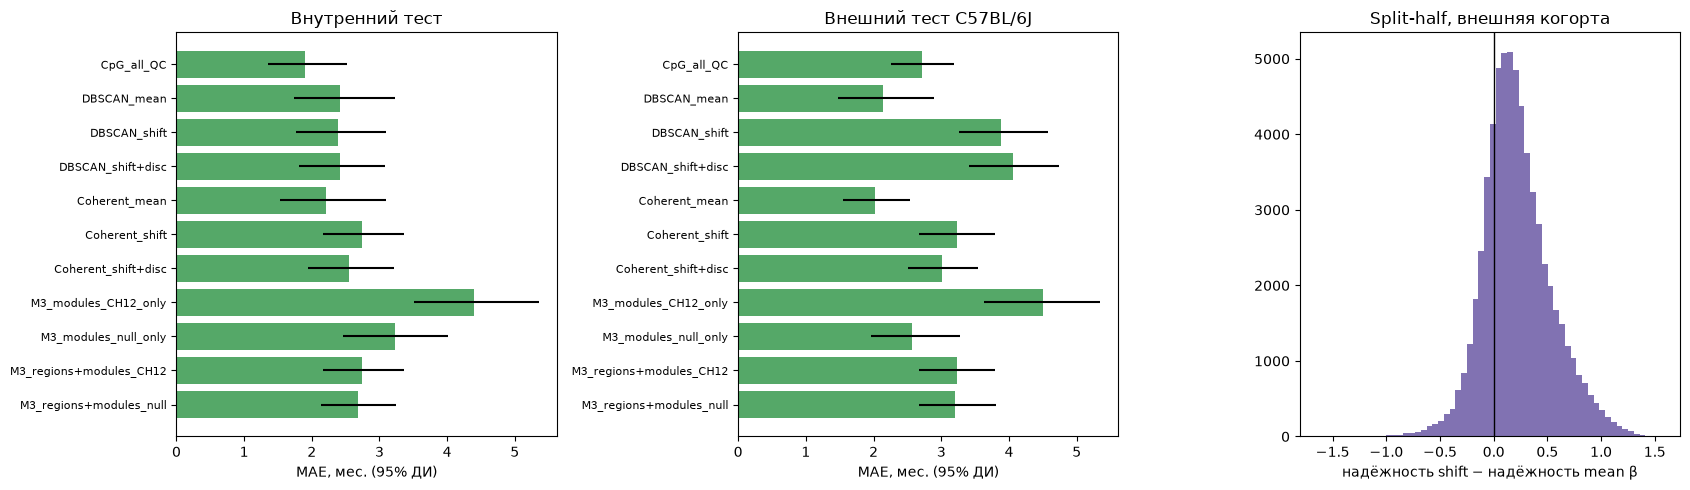

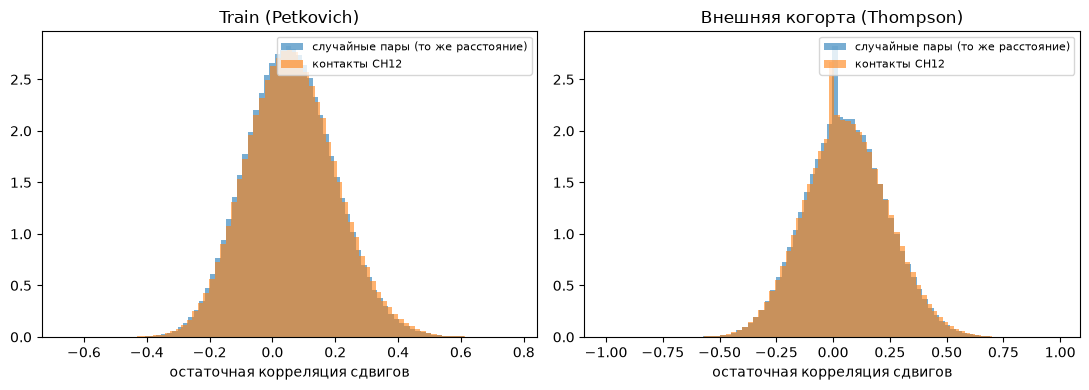

Архив: /tmp/work/results_pipeline2.zip


In [18]:
cr = pd.DataFrame([{"representation": rep, **core.age_acceleration(PRED[(rep, "internal_test")], y[R["internal_test"]],
                                                                    PRED[(rep, "CR")], y[R["CR"]])} for rep in MODELS])
cr.to_csv(os.path.join(OUT, "CR_age_acceleration.tsv"), sep="\t", index=False)
print(cr.round(3).to_string(index=False))

import matplotlib.pyplot as plt
res = pd.DataFrame(ROWS); res.to_csv(os.path.join(OUT, "all_prediction_metrics.tsv"), sep="\t", index=False)
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
order = list(MODELS)
for k, s in enumerate(["internal_test", "external_B6"]):
    d = res[res.split == s].set_index("representation").reindex(order)
    ax[k].barh(range(len(d)), d.MAE, xerr=[d.MAE - d.MAE_lo, d.MAE_hi - d.MAE], color="#55A868")
    ax[k].set_yticks(range(len(d))); ax[k].set_yticklabels(d.index, fontsize=8); ax[k].invert_yaxis()
    ax[k].set_xlabel("MAE, мес. (95% ДИ)"); ax[k].set_title({"internal_test": "Внутренний тест", "external_B6": "Внешний тест C57BL/6J"}[s])
rm, rs = rel_store["external_B6"]; okr = np.isfinite(rm) & np.isfinite(rs)
ax[2].hist(rs[okr] - rm[okr], bins=60, color="#8172B2"); ax[2].axvline(0, color="k", lw=1)
ax[2].set_xlabel("надёжность shift − надёжность mean β"); ax[2].set_title("Split-half, внешняя когорта")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_pipeline2_summary.png"), dpi=150); plt.show()

if RUN_HIC and "train" in M3:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for k, s in enumerate(["train", "external_B6"]):
        rc, rn, rm_ = M3[s]
        ax[k].hist(rn, bins=80, alpha=.6, density=True, label="случайные пары (то же расстояние)")
        ax[k].hist(rc, bins=80, alpha=.6, density=True, label="контакты CH12")
        ax[k].set_title({"train": "Train (Petkovich)", "external_B6": "Внешняя когорта (Thompson)"}[s])
        ax[k].set_xlabel("остаточная корреляция сдвигов"); ax[k].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, "fig_M3_contact_comethylation.png"), dpi=150); plt.show()

pd.DataFrame([{"representation": r, "sample_id": M.ids[i], "split": s, "age_months": y[i], "pred": p}
              for (r, s), pp in PRED.items() for i, p in zip(R[s], pp)]).to_csv(os.path.join(OUT, "predictions.tsv"), sep="\t", index=False)
for name, reg in [("DBSCAN", reg_db), ("Coherent", reg_dyn)]:
    o = reg.copy(); o["chr"] = "chr" + (o.chr + 1).astype(str); o["start"] = o.start - 1
    o[["chr", "start", "end", "n_cpg"]].to_csv(os.path.join(OUT, f"regions_{name}.bed"), sep="\t", header=False, index=False)
json.dump(dict(SEED=SEED, MIN_COV=MIN_COV, MIN_FRAC_TRAIN=MIN_FRAC_TRAIN, QC_FRAC_CPG=QC_FRAC_CPG, DBSCAN_EPS=DBSCAN_EPS,
               DBSCAN_MINPTS=DBSCAN_MINPTS, segmentation_penalty="2*log(n)", min_segment_cpg=3, RUN_HIC=RUN_HIC),
          open(os.path.join(OUT, "config.json"), "w"), indent=2)
meta.to_csv(os.path.join(OUT, "samples_and_split.tsv"), sep="\t", index=False)
shutil.make_archive(os.path.join(WORK, "results_pipeline2"), "zip", OUT)
print("Архив:", os.path.join(WORK, "results_pipeline2.zip"))
if IN_COLAB:
    from google.colab import files
    files.download(os.path.join(WORK, "results_pipeline2.zip"))